In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

1 Conjunto de Usinas - 1 estação meterológica

| Conjunto | Estação | Código | Distância |
| :--- | :--- | :--- | :--- |
| Conj. Dracena | DRACENA | A762 | 3,8 km |
| Conj. Pedranópolis | JALES | A733 | 58,9 km |
| Conj. Castilho | DRACENA | A762 | 73,90 km |
| Conj. Pereira Barreto | VALPARAISO | A734 | 86,40 km |

Mas todos os conjutos de Usinas estão localizados na mesma região: Noroeste/Oeste paulista

| Usina | Estação | Código | Distância (km) |
| :--- | :--- | :--- | ---: |
| Conj. Castilho | DRACENA | A762 | 73.90 |
| Conj. Castilho | VALPARAISO | A734 | 85.42 |
| Conj. Dracena | DRACENA | A762 | 3.78 |
| Conj. Dracena | PRESIDENTE PRUDENTE | A707 | 76.42 |
| Conj. Dracena | VALPARAISO | A734 | 69.68 |
| Conj. Pedranópolis | CAMPINA VERDE | A519 | 90.48 |
| Conj. Pedranópolis | JALES | A733 | 58.86 |
| Conj. Pedranópolis | JOSE BONIFACIO | A735 | 99.17 |
| Conj. Pereira Barreto | DRACENA | A762 | 96.35 |
| Conj. Pereira Barreto | JALES | A733 | 89.14 |
| Conj. Pereira Barreto | VALPARAISO | A734 | 86.40 |

# Avaliação da qualidade dos dados. Apenas nas variáveis relevantes para a modelagem

### Variáveis

| Variável                           | Justificativa                                           |
| ---------------------------------- | ------------------------------------------------------- |
| **RADIACAO GLOBAL(Kj/m²)**         | Principal variável explicativa da geração fotovoltaica. |
| **TEMPERATURA DO AR - BULBO SECO** | A eficiência dos módulos varia com a temperatura.       |
| **UMIDADE RELATIVA DO AR**         | Pode indicar nebulosidade e condições atmosféricas.     |
| **PRECIPITAÇÃO TOTAL**             | Associada à cobertura de nuvens e eventos extremos.     |


| Variável            | Justificativa                                                                                       |
| ------------------- | --------------------------------------------------------------------------------------------------- |
| Velocidade do vento | O vento resfria os módulos, aumentando a eficiência.                                                |
| Rajada máxima       | Pode indicar mudanças bruscas nas condições atmosféricas.                                           |
| Pressão atmosférica | Pode ajudar na caracterização de sistemas meteorológicos, mas normalmente tem menor impacto direto. |


"Todas as informações divulgadas pelo Instituto estão em horário UTC, para a conversão com o horário oficial de Brasília, é necessário subtrair 3 horas."


Os dados das estações automáticas são brutos e não passam por um processo de consistência (validação).


Possíveis falhas decorrentes de problemas (pane) nos sensores, comunicação nas estações ou ausência de observações estão identificadas pelo número "9999", o termo "Null" ou estarão em branco. Os dados que não estão disponíveis no portal do Inmet (consulta dados) são inexistentes.

## Funções

In [ ]:
def extract_normalize_stations(estacao):
    path = f"/content/dados_{estacao}_H_2025-01-01_2025-12-31.csv"

    # Carrega substituindo a vírgula por ponto decimal (evita que fiquem como 'object')
    df = pd.read_csv(path, sep=";", skiprows=9, decimal=",")
    df['Hora Medicao'] = df['Hora Medicao'].astype(str).str.zfill(4)

    # Cria o formato de hora padrão (HH:MM:SS)
    df['time'] = df['Hora Medicao'].str[:2] + ":00:00"
    df = df.rename(columns={"Data Medicao": "date"})

    # 3. Junta as colunas de texto 'date' e 'time' em uma coluna única do tipo Datetime (Ainda em UTC)
    df['data_hora_utc'] = pd.to_datetime(df['date'] + ' ' + df['time'], format='%Y-%m-%d %H:%M:%S')

    # 4. Ajuste de Engenharia de Dados: Converte UTC para UTC-3 (Subtrai 3 horas)
    df['datetime'] = df['data_hora_utc'] - pd.Timedelta(hours=3)

    # 5. Organiza o DataFrame: descarta as colunas intermediárias de texto que não usaremos mais
    # Nota: Removi o 'Unnamed: 22' daqui para evitar erro caso o arquivo varie de formato, tratamos isso no filtro final
    df = df.drop(columns=['date', 'time', 'data_hora_utc', 'Hora Medicao'], errors='ignore')

    # 6. Extrair os dados de horário diurno (07:00 às 17:00) conforme recomendação da literatura para remoção de ruído noturno
    df = df[(df['datetime'].dt.hour >= 7) & (df['datetime'].dt.hour <= 17)].copy()

    # [Engenharia de Recursos dos Artigos] - Codificação Cíclica do Horário (Seno/Cosseno)
    # Permite ao modelo de ML entender que 23h está perto de 00h e ajuda na linearidade temporal
    df['hour_sin'] = np.sin(2 * np.pi * df['datetime'].dt.hour / 24.0)
    df['hour_cos'] = np.cos(2 * np.pi * df['datetime'].dt.hour / 24.0)

    # Codificação Cíclica do Mês (Sazonalidade do ano)
    df['month_sin'] = np.sin(2 * np.pi * df['datetime'].dt.month / 12.0)
    df['month_cos'] = np.cos(2 * np.pi * df['datetime'].dt.month / 12.0)

    # 7. Extrair apenas as colunas de Interesse (Removendo variáveis de hardware e mantendo as meteorológicas/temporais mais relevantes)
    colunas_interesse = [
        'datetime',
        'hour_sin', 'hour_cos',
        'month_sin', 'month_cos',
        'RADIACAO GLOBAL(Kj/m²)',                                # A mais crítica (Alta prioridade)
        'TEMPERATURA DA AR - BULBO SECO, HORARIA(°C)',          # Alta relevância térmica
        'TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C)',
        'TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C)',
        'UMIDADE RELATIVA DO AR, HORARIA(%)',                   # Alta relevância (Atenuação/Nuvens)
        'UMIDADE REL. MAX. NA HORA ANT. (AUT)(%)',
        'UMIDADE REL. MIN. NA HORA ANT. (AUT)(%)',
        'PRECIPITACAO TOTAL, HORARIO(mm)',                      # Indicador indireto de nuvens pesadas
        'VENTO, VELOCIDADE HORARIA(m/s)',                       # Resfriamento mecânico das células
        'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)',  # Variável de suporte meteorológico
        'TEMPERATURA DO PONTO DE ORVALHO(°C)'                   # Variável de suporte meteorológico
    ]

    # Ajustando dinamicamente os nomes das colunas caso haja pequenas variações de grafia no CSV original (ex: DA AR vs DO AR)
    colunas_existentes = [col for col in colunas_interesse if col in df.columns or col in ['datetime', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']]

    df = df[colunas_existentes]

    # Ordena cronologicamente para garantir a consistência de séries temporais
    df = df.sort_values(by='datetime').reset_index(drop=True)

    return df

In [ ]:
def analyze_data_quality(df):
    """
    Executa a análise de valores ausentes, estatísticas descritivas e
    validação de consistência física para os dados meteorológicos.
    """
    quality_report = {}

    # Lista de colunas numéricas a serem validadas (excluindo a coluna de tempo)
    numeric_cols = [col for col in df.columns if col != 'datetime' and df[col].dtype != 'object']

    for col in numeric_cols:
        col_report = {}

        # 1. Percentual de valores ausentes (Missing Values)
        total_rows = len(df)
        missing_count = df[col].isna().sum()
        missing_pct = (missing_count / total_rows) * 100
        col_report['valores_ausentes_pct'] = round(missing_pct, 2)

        # 2. Estatísticas descritivas básicas
        col_report['minimo'] = df[col].min()
        col_report['maximo'] = df[col].max()
        col_report['media'] = df[col].mean()
        col_report['desvio_padrao'] = df[col].std()

        # 3. Identificação de inconsistências físicas (Fisicamente Impossíveis)
        # Inicializa contador de erros físicos
        physical_errors = 0

        # Regra para Radiação Global (Não pode ser negativa)
        if 'RADIACAO' in col.upper():
            # Conta se há radiação negativa no período diurno filtrado
            physical_errors = (df[col] < 0).sum()

        # Regras para Umidade Relativa (Deve estar estritamente entre 0% e 100%)
        elif 'UMIDADE' in col.upper():
            physical_errors = ((df[col] < 0) | (df[col] > 100)).sum()

        # Regra para Precipitação (Não pode ser negativa)
        elif 'PRECIPITACAO' in col.upper():
            physical_errors = (df[col] < 0).sum()

        # Regra para Velocidade do Vento (Não pode ser negativa)
        elif 'VENTO' in col.upper() and 'VELOCIDADE' in col.upper():
            physical_errors = (df[col] < 0).sum()

        # Regra para Pressão Atmosférica (Valores realistas ao nível da estação geralmente > 0)
        elif 'PRESSAO' in col.upper():
            physical_errors = (df[col] <= 0).sum()

        col_report['erros_fisicos_detectados'] = int(physical_errors)

        quality_report[col] = col_report

    # Transforma o dicionário em um DataFrame legível para o usuário
    report_df = pd.DataFrame(quality_report).T

    return report_df

In [ ]:
def plot_variable_distributions(df, columns_to_plot=None):
    """
    Gera automaticamente Boxplots e Histogramas para as variáveis selecionadas
    permitindo identificar visualmente Outliers e a dispersão dos dados.
    """
    if columns_to_plot is None:
        # Seleciona colunas meteorológicas principais ignorando as transformações cíclicas (sin/cos)
        columns_to_plot = [col for col in df.columns if df[col].dtype != 'object' and 'datetime' not in col and 'sin' not in col and 'cos' not in col]

    for col in columns_to_plot:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Histograma com KDE (Distribuição)
        sns.histplot(df[col].dropna(), kde=True, ax=axes[0], color='skyblue')
        axes[0].set_title(f'Distribuição (Histograma): {col}')
        axes[0].set_xlabel(col)
        axes[0].set_ylabel('Frequência')

        # Boxplot (Identificação visual de Outliers)
        sns.boxplot(x=df[col].dropna(), ax=axes[1], color='lightcoral')
        axes[1].set_title(f'Análise de Outliers (Boxplot): {col}')
        axes[1].set_xlabel(col)

        plt.tight_layout()
        plt.show()

Fonte: https://portal.inmet.gov.br/paginas/catalogoaut

In [ ]:
df_estacoes = pd.read_csv('/content/Catálogo de Estações Automáticas.csv')

In [ ]:
df_estacoes.head(1)

,Nome,UF,Situação,Latitude,Longitude,Altitude,Data de Instalação,Código
0,AFONSO CLAUDIO,ES,Operante,"-20,104167","-41,106944","507,48",23/09/2011,A657


## Dracena A762

https://tempo.inmet.gov.br/TabelaEstacoes/A762

In [ ]:
print(df_estacoes[df_estacoes['Nome']=='DRACENA'])

        Nome  UF Situação    Latitude   Longitude Altitude Data de Instalação  \
132  DRACENA  SP     Pane  -21,457778  -51,552222      383         02/11/2016   

    Código  
132   A762  


In [ ]:
df_dracena = extract_normalize_stations('A762')
df_dracena.head(1)

,datetime,hour_sin,hour_cos,month_sin,month_cos,RADIACAO GLOBAL(Kj/m²),TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),"UMIDADE RELATIVA DO AR, HORARIA(%)",UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),"PRECIPITACAO TOTAL, HORARIO(mm)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",TEMPERATURA DO PONTO DE ORVALHO(°C)
0,2025-01-01 07:00:00,0.965926,-0.258819,0.5,0.866025,383.0,24.5,22.7,100.0,100.0,88.0,0.0,3.3,967.7,24.5


In [ ]:
df_dracena.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4015 entries, 0 to 4014
Data columns (total 15 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   datetime                                              4015 non-null   datetime64[ns]
 1   hour_sin                                              4015 non-null   float64       
 2   hour_cos                                              4015 non-null   float64       
 3   month_sin                                             4015 non-null   float64       
 4   month_cos                                             4015 non-null   float64       
 5   RADIACAO GLOBAL(Kj/m²)                                3090 non-null   float64       
 6   TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C)             3090 non-null   float64       
 7   TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C)             3090 non-null   float64 

In [ ]:
df_dracena_qualidade = analyze_data_quality(df_dracena)
df_dracena_qualidade

,valores_ausentes_pct,minimo,maximo,media,desvio_padrao,erros_fisicos_detectados
hour_sin,0.00,-0.965926,0.965926,1.243782e-16,0.674284,0.0
hour_cos,0.00,-1.000000,-0.258819,-6.905231e-01,0.262010,0.0
month_sin,0.00,-1.000000,1.000000,-5.381100e-03,0.705720,0.0
month_cos,0.00,-1.000000,1.000000,-2.372672e-03,0.708643,0.0
RADIACAO GLOBAL(Kj/m²),23.04,-3.600000,3947.100000,1.674386e+03,1076.073805,85.0
TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),23.04,4.900000,40.800000,2.658142e+01,5.882691,0.0
TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),23.04,3.300000,39.100000,2.483599e+01,5.795688,0.0
"UMIDADE RELATIVA DO AR, HORARIA(%)",26.08,11.000000,100.000000,5.687230e+01,20.241320,0.0
UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),26.85,12.000000,100.000000,6.213347e+01,21.311349,0.0
UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),26.85,11.000000,100.000000,5.408648e+01,19.108004,0.0


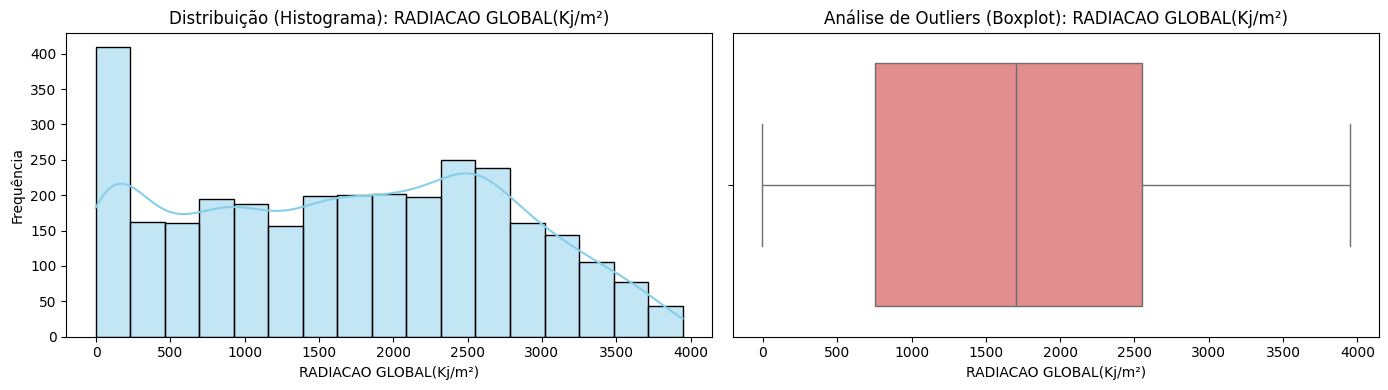

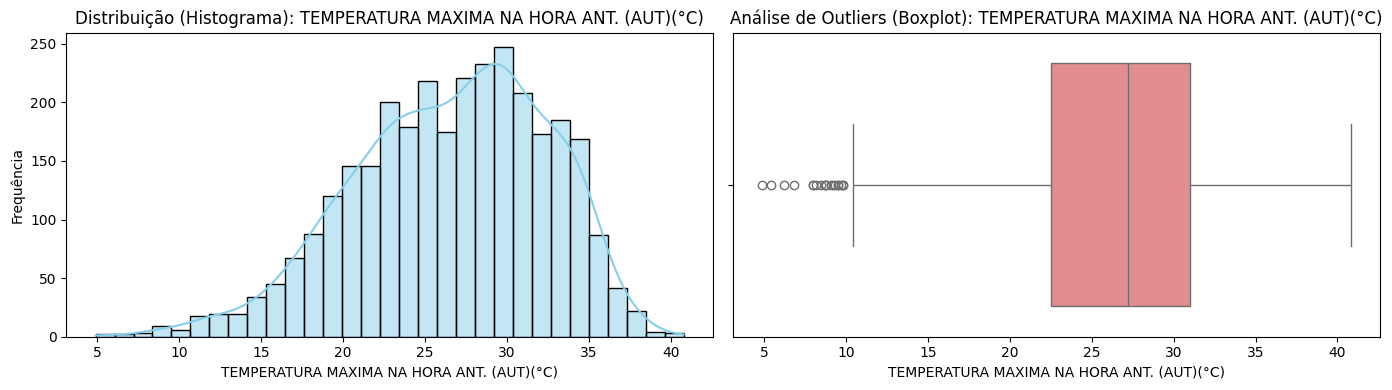

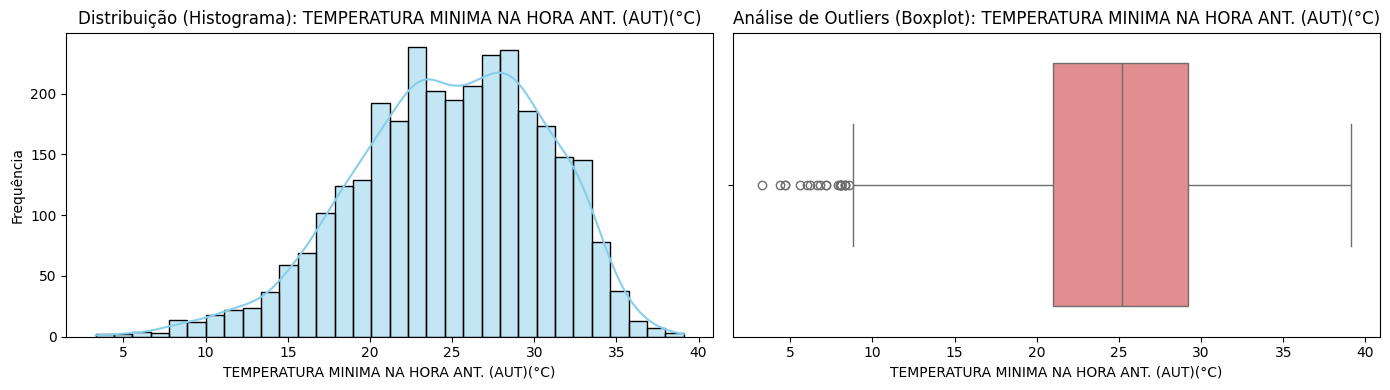

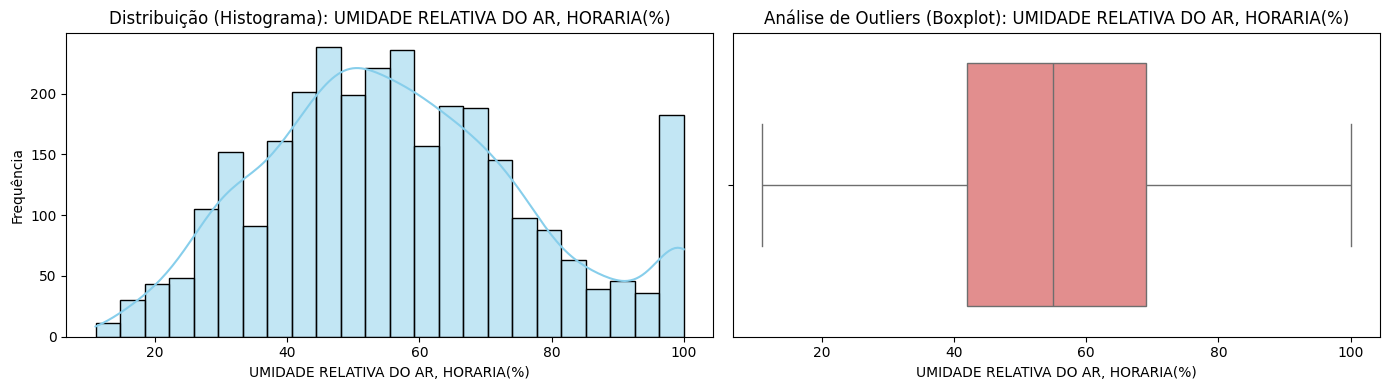

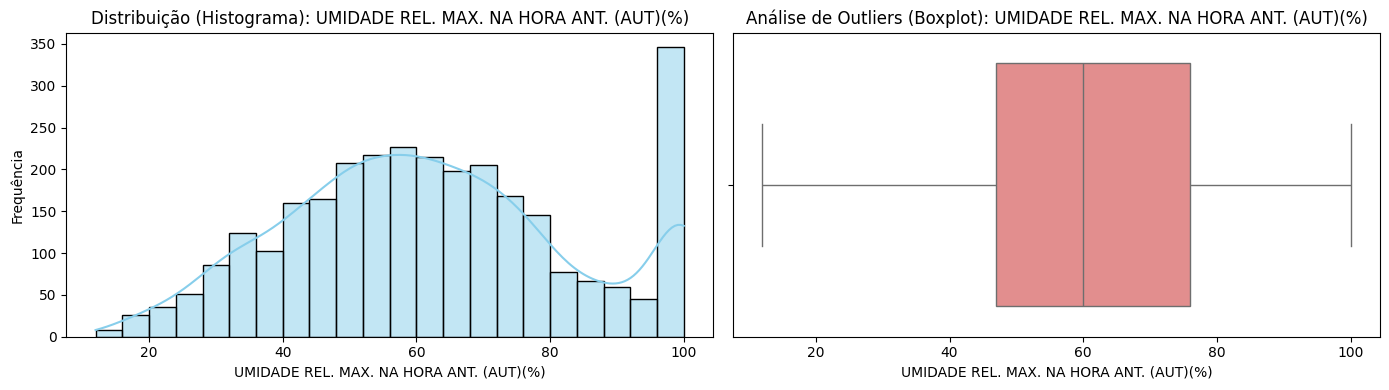

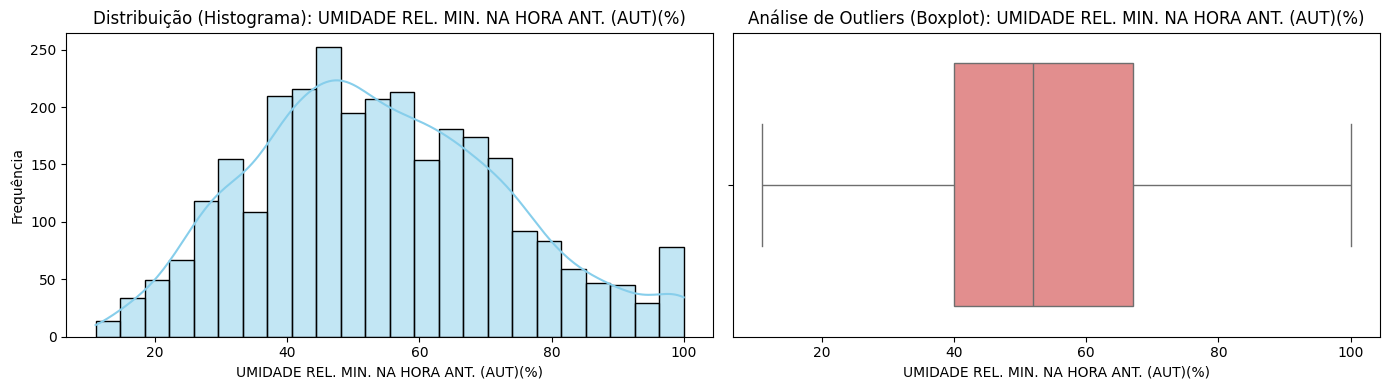

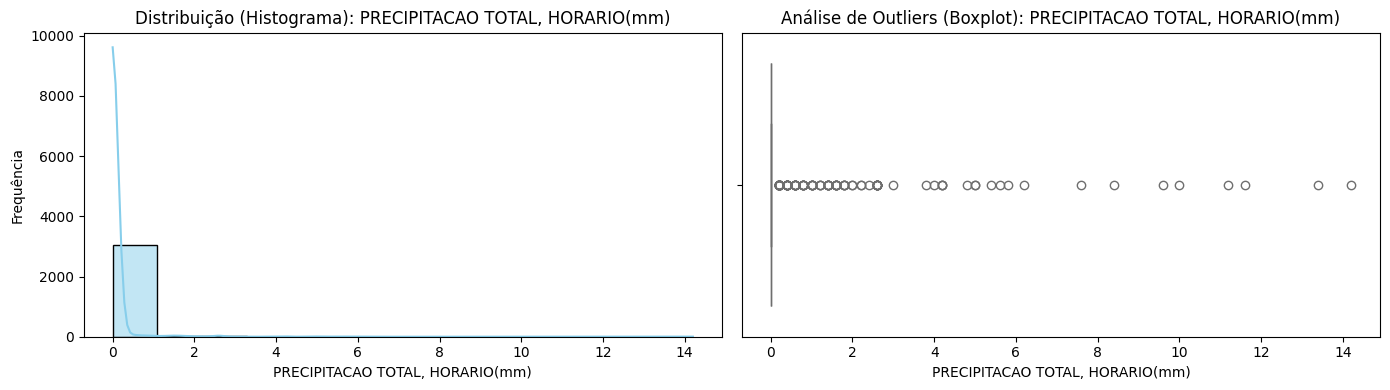

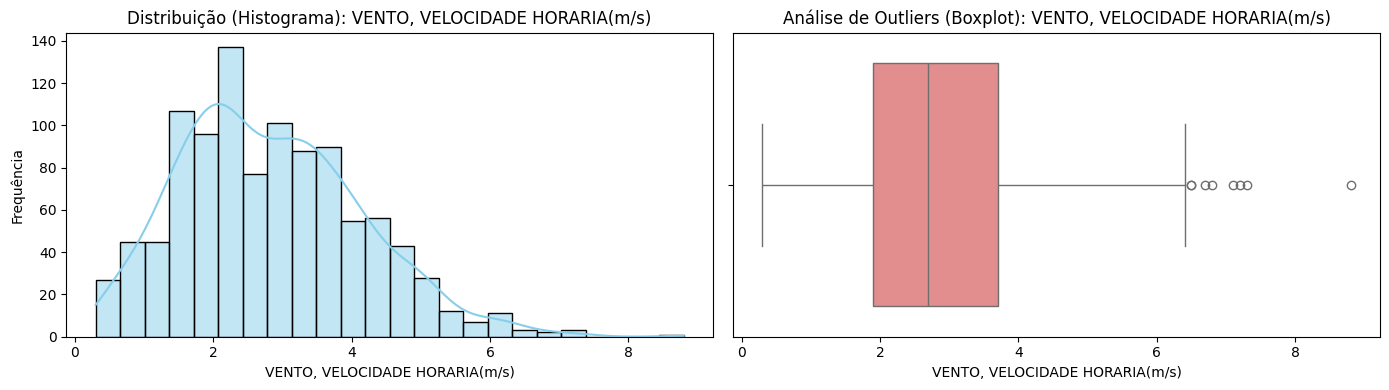

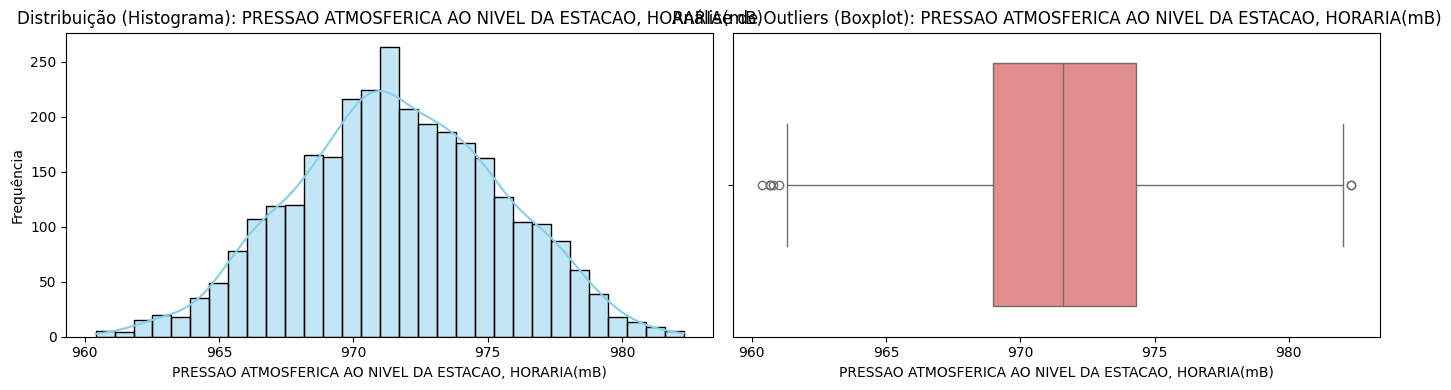

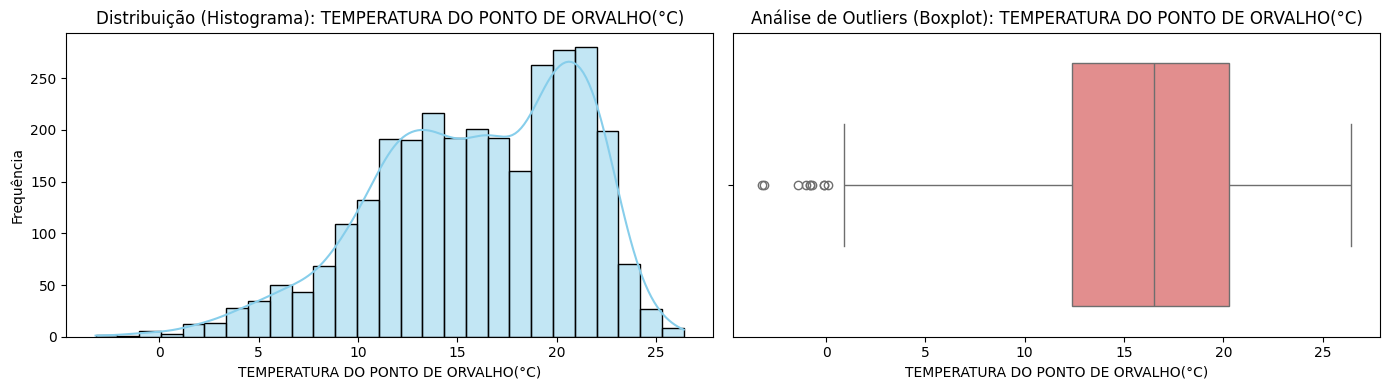

In [ ]:
plot_variable_distributions(df_dracena)

### Problemas

###### Dados Ausentes



* **Velocidade do Vento** (74.25% de NaNs): Três quartos dos dados de vento desta usina desapareceram. Isso indica uma falha prolongada ou falta de manutenção no anemômetro da estação. Descartar variável para não induzir o modelo a erro

--------

Descartar essa variável

*   **Radiação, Temperatura e Pressão** (~23.04% de NaNs) / Umidade (~26.85% de NaNs): O fato de quase todas as variáveis principais compartilharem a mesma faixa de perda (~23-26%) sugere um apagão sistêmico da estação (falha de energia, perda de conexão ou desligamento da usina por cerca de 2 a 3 meses do ano). Como são variáveis cruciais (especialmente a Radiação), você não pode descartá-las. A interpolação linear simples falhará se os apagões forem de muitos dias seguidos. Será necessário remover os blocos de dias em que a estação esteve completamente desligada.

###### Inconsistência Física Gravíssima na Radiação Solar

* Radiação Mínima de -3.6 Kj/m² com 85 erros físicos detectados: Matematicamente, a radiação solar global não pode ser negativa, especialmente no intervalo diurno filtrado (07h às 17h).
* O histograma da página 1 do relatório comprova um comportamento ligeiramente desalinhado à esquerda. Isso aponta para um erro de calibração do piranômetro (ruído de fundo elétrico gerando leituras negativas discretas quando há sombra densa ou nuvens pesadas).



--------

Substitua todos os valores negativos de radiação estritamente por 0.0 antes do treino

###### Comportamento das Variáveis Térmicas e Umidade (Clima Consistente)

* **Amplitude Térmica Coerente**: A temperatura máxima chegou a $40.8^\circ\text{C}$ e a mínima a $3.3^\circ\text{C}$. O desvio padrão ($\sim 5.8^\circ\text{C}$) e os boxplots da página 1 mostram distribuições térmicas bem comportadas e contínuas, sem outliers absurdos fora da realidade brasileira.

* Umidade Relativa (0 erros físicos): A umidade respeitou o limite físico, variando de um mínimo seco de $11\%$ até a saturação de $100\%$. Olhando o histograma da página 2, nota-se uma distribuição bimodal ou espalhada, muito comum em regiões que enfrentam estações secas severas e frentes de chuva intensa.

###### Precipitação Acumulada

* Precipitação Máxima de 14.2 mm: Indica chuvas moderadas na hora medida. O boxplot na página 2 mostra uma imensa quantidade de "pontinhos" (outliers estatísticos). No caso da chuva, isso é normal e esperado: a maior parte do tempo não chove (valor 0.0), transformando qualquer chuva em um extremo estatístico.

-------
Impacto no ML: Modelos de árvore (XGBoost/LightGBM) lidam muito bem com essa assimetria da chuva.

##### Recomendação

Remova a coluna **VENTO, VELOCIDADE HORARIA(m/s).** Ela tem mais ruído/vazio do que informação útil.

**Trate a radiação negativa:** Force valores menores que zero a virarem zero.

**Tratamento de NaNs (23%):** Utilize uma estratégia de máscara. Remova as linhas inteiras onde a RADIACAO GLOBAL for nula (pois sem o alvo principal ou o preditor vital, o modelo não aprende). Não tente preencher lacunas de semanas usando médias, ou o modelo perderá a capacidade de prever a intermitência de dias nublados.

## Jales A733

https://tempo.inmet.gov.br/TabelaEstacoes/A733

In [ ]:
print(df_estacoes[df_estacoes['Nome']=='JALES'])

      Nome  UF  Situação Latitude Longitude Altitude Data de Instalação Código
140  JALES  SP  Operante  -20,165   -50,595   460,44         21/08/2007   A733


In [ ]:
df_jales = extract_normalize_stations('A733')
df_jales.head(1)

,datetime,hour_sin,hour_cos,month_sin,month_cos,RADIACAO GLOBAL(Kj/m²),TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),"UMIDADE RELATIVA DO AR, HORARIA(%)",UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),"PRECIPITACAO TOTAL, HORARIO(mm)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",TEMPERATURA DO PONTO DE ORVALHO(°C)
0,2025-01-01 07:00:00,0.965926,-0.258819,0.5,0.866025,NaN,23.4,21.7,87.0,92.0,86.0,0.0,3.2,959.7,21.0


In [ ]:
df_jales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4015 entries, 0 to 4014
Data columns (total 15 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   datetime                                              4015 non-null   datetime64[ns]
 1   hour_sin                                              4015 non-null   float64       
 2   hour_cos                                              4015 non-null   float64       
 3   month_sin                                             4015 non-null   float64       
 4   month_cos                                             4015 non-null   float64       
 5   RADIACAO GLOBAL(Kj/m²)                                154 non-null    float64       
 6   TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C)             4008 non-null   float64       
 7   TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C)             4008 non-null   float64 

Muito pouco dados de radiação :/

In [ ]:
df_jales_qualidade = analyze_data_quality(df_jales)
df_jales_qualidade

,valores_ausentes_pct,minimo,maximo,media,desvio_padrao,erros_fisicos_detectados
hour_sin,0.00,-0.965926,0.965926,1.243782e-16,0.674284,0.0
hour_cos,0.00,-1.000000,-0.258819,-6.905231e-01,0.262010,0.0
month_sin,0.00,-1.000000,1.000000,-5.381100e-03,0.705720,0.0
month_cos,0.00,-1.000000,1.000000,-2.372672e-03,0.708643,0.0
RADIACAO GLOBAL(Kj/m²),96.16,0.000000,354.400000,1.834708e+02,108.396036,0.0
TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),0.17,4.800000,39.700000,2.727353e+01,5.342613,0.0
TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),0.17,4.200000,37.700000,2.533985e+01,5.290846,0.0
"UMIDADE RELATIVA DO AR, HORARIA(%)",0.60,9.000000,100.000000,5.538963e+01,21.619964,0.0
UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),0.70,10.000000,100.000000,6.079383e+01,22.270385,0.0
UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),0.70,8.000000,100.000000,5.315676e+01,21.574949,0.0


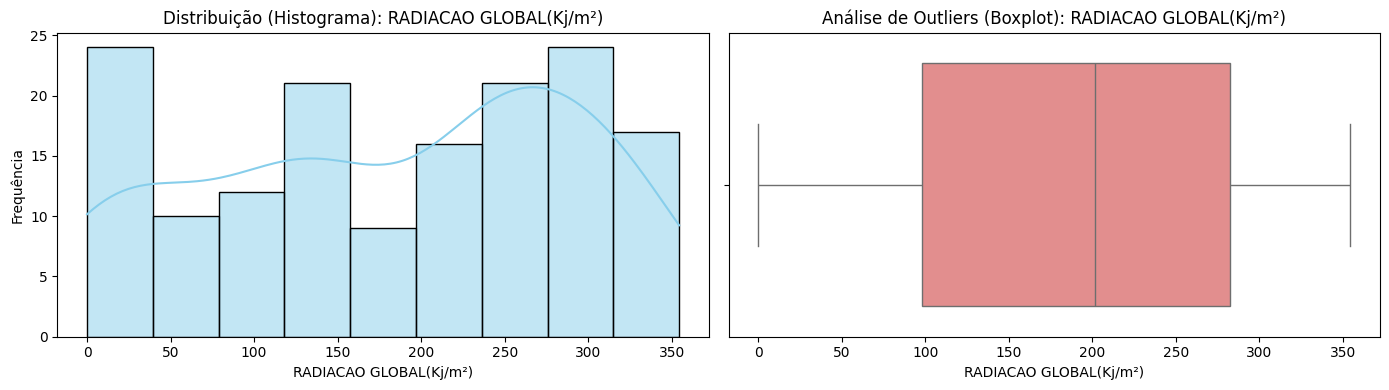

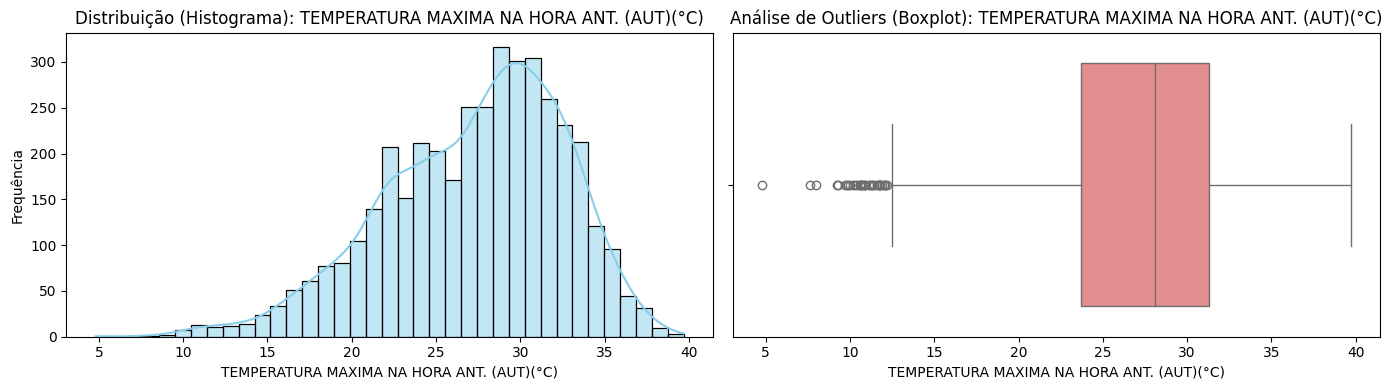

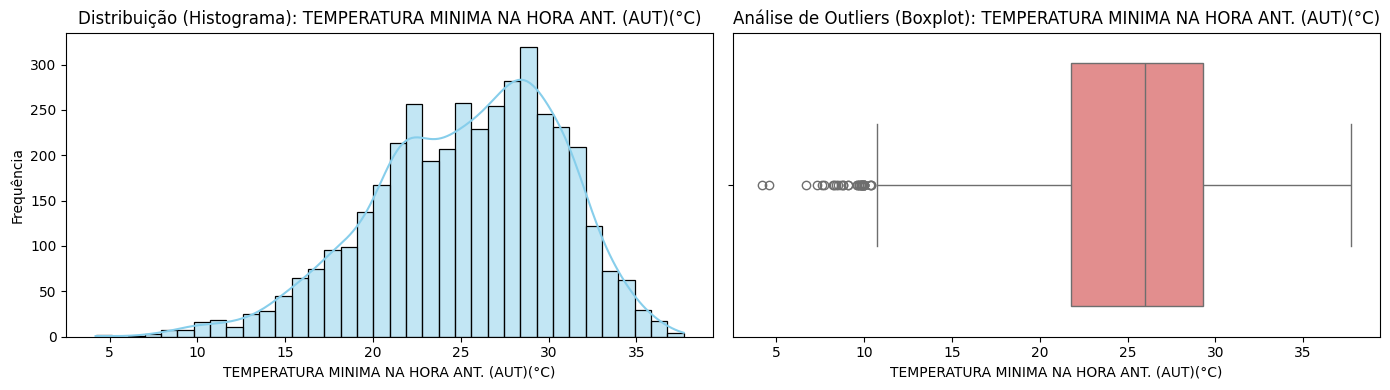

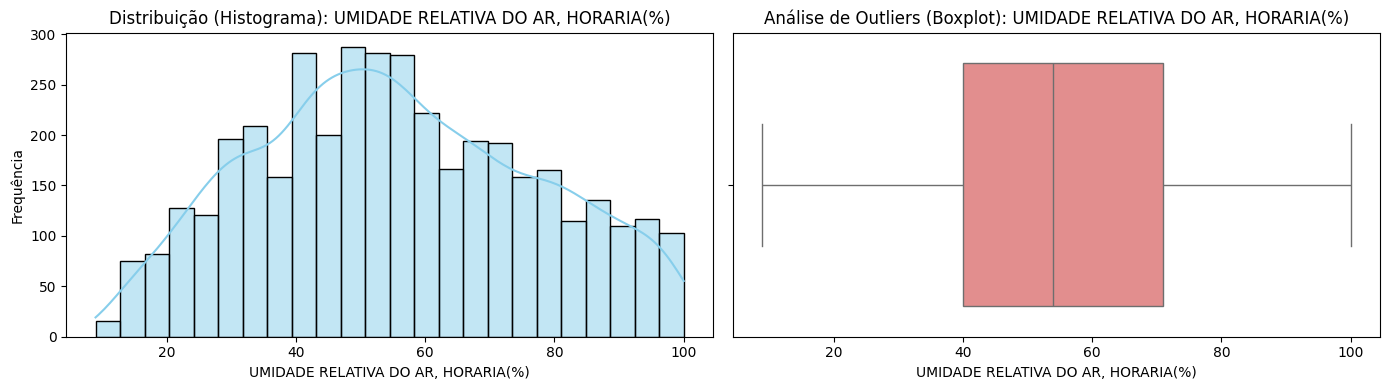

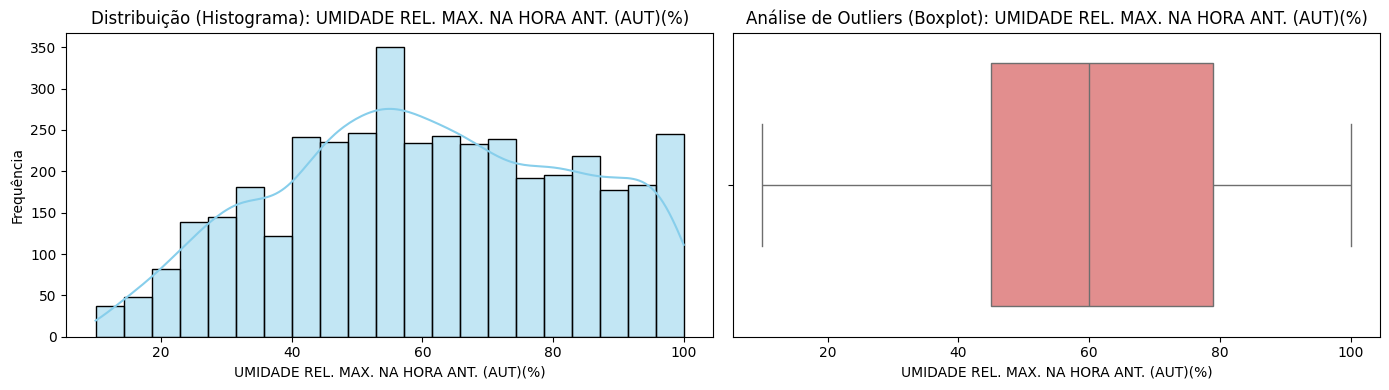

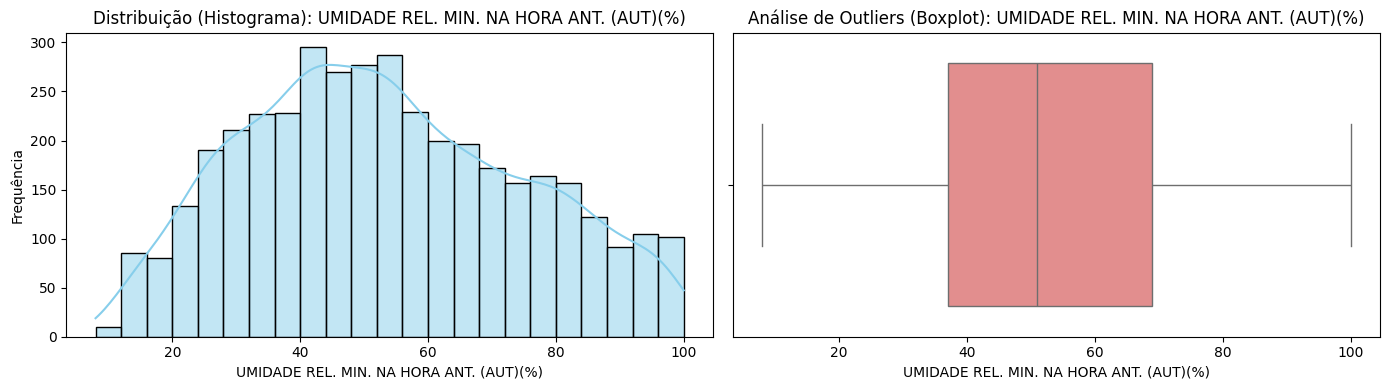

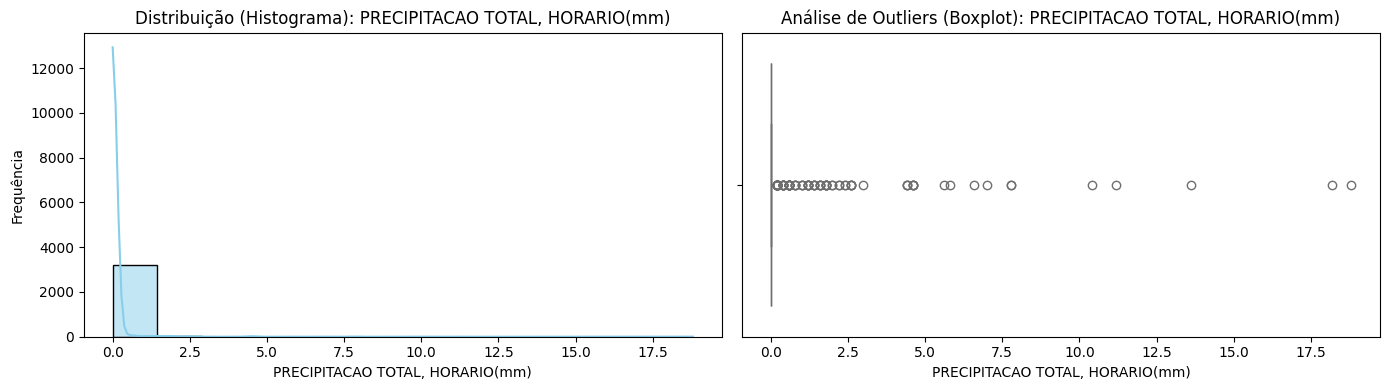

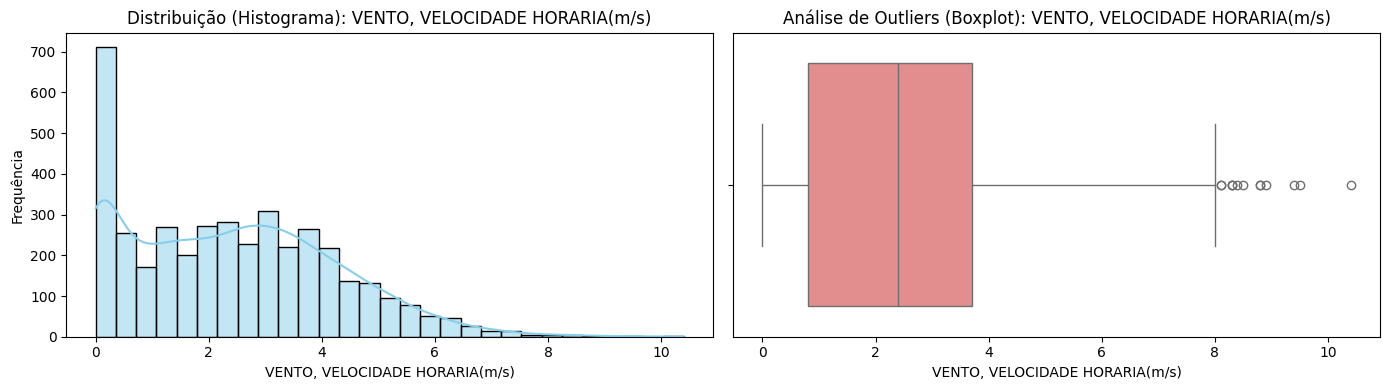

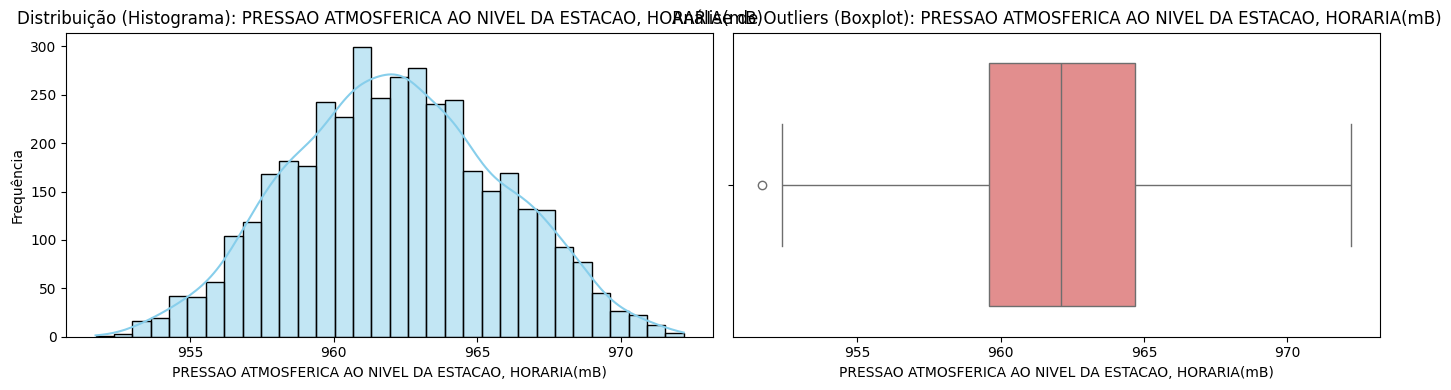

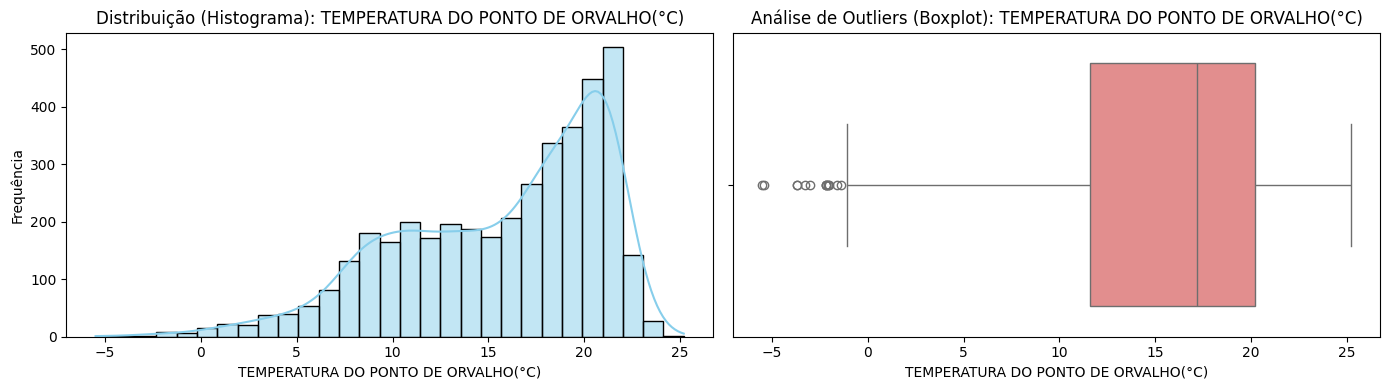

In [ ]:
plot_variable_distributions(df_jales)

Radiação  (96.16% de Dados Ausentes)    

A velocidade do vento está praticamente perfeita, com apenas 0,17% de NaNs e uma distribuição excelente (máxima de $10.4\text{ m/s}$).    

Temperatura e Umidade em Jales também beiram a perfeição (menos de $1\%$ de perda).

## Val Paraíso A734

In [ ]:
print(df_estacoes[df_estacoes['Nome']=='VALPARAISO'])

           Nome  UF  Situação    Latitude   Longitude Altitude  \
160  VALPARAISO  SP  Operante  -21,319167  -50,930278    381,9   

    Data de Instalação Código  
160         29/08/2007   A734  


In [ ]:
df_valparaiso = extract_normalize_stations('A734')
df_valparaiso.head(1)

,datetime,hour_sin,hour_cos,month_sin,month_cos,RADIACAO GLOBAL(Kj/m²),TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),"UMIDADE RELATIVA DO AR, HORARIA(%)",UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),"PRECIPITACAO TOTAL, HORARIO(mm)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",TEMPERATURA DO PONTO DE ORVALHO(°C)
0,2025-01-01 07:00:00,0.965926,-0.258819,0.5,0.866025,314.9,24.2,22.2,82.0,89.0,82.0,0.0,2.1,968.2,21.0


In [ ]:
df_valparaiso.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4015 entries, 0 to 4014
Data columns (total 15 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   datetime                                              4015 non-null   datetime64[ns]
 1   hour_sin                                              4015 non-null   float64       
 2   hour_cos                                              4015 non-null   float64       
 3   month_sin                                             4015 non-null   float64       
 4   month_cos                                             4015 non-null   float64       
 5   RADIACAO GLOBAL(Kj/m²)                                3935 non-null   float64       
 6   TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C)             4009 non-null   float64       
 7   TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C)             4009 non-null   float64 

In [ ]:
df_valparaiso_qualidade = analyze_data_quality(df_valparaiso)
df_valparaiso_qualidade

,valores_ausentes_pct,minimo,maximo,media,desvio_padrao,erros_fisicos_detectados
hour_sin,0.00,-0.965926,0.965926,1.243782e-16,0.674284,0.0
hour_cos,0.00,-1.000000,-0.258819,-6.905231e-01,0.262010,0.0
month_sin,0.00,-1.000000,1.000000,-5.381100e-03,0.705720,0.0
month_cos,0.00,-1.000000,1.000000,-2.372672e-03,0.708643,0.0
RADIACAO GLOBAL(Kj/m²),1.99,-3.500000,3878.800000,1.632692e+03,1069.757014,90.0
TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),0.15,2.300000,40.500000,2.741347e+01,5.999203,0.0
TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),0.15,1.700000,39.300000,2.542986e+01,5.968396,0.0
"UMIDADE RELATIVA DO AR, HORARIA(%)",0.17,7.000000,97.000000,5.437051e+01,21.748551,0.0
UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),0.15,7.000000,97.000000,5.976029e+01,22.164108,0.0
UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),0.20,8.000000,96.000000,5.245745e+01,21.900597,0.0


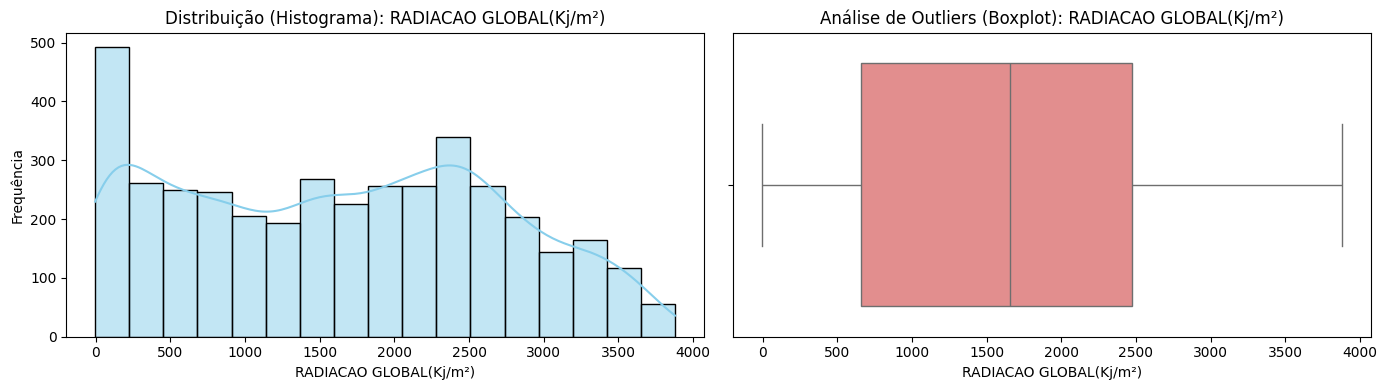

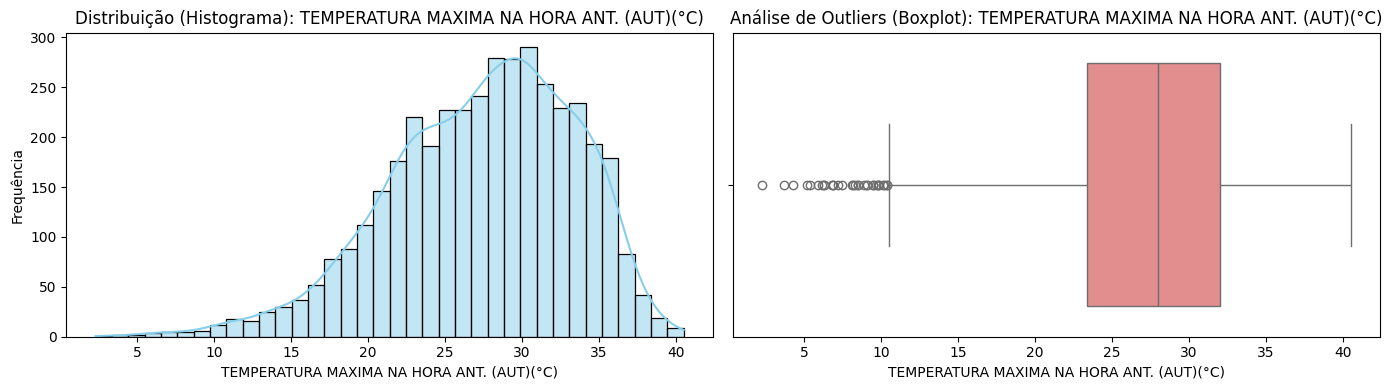

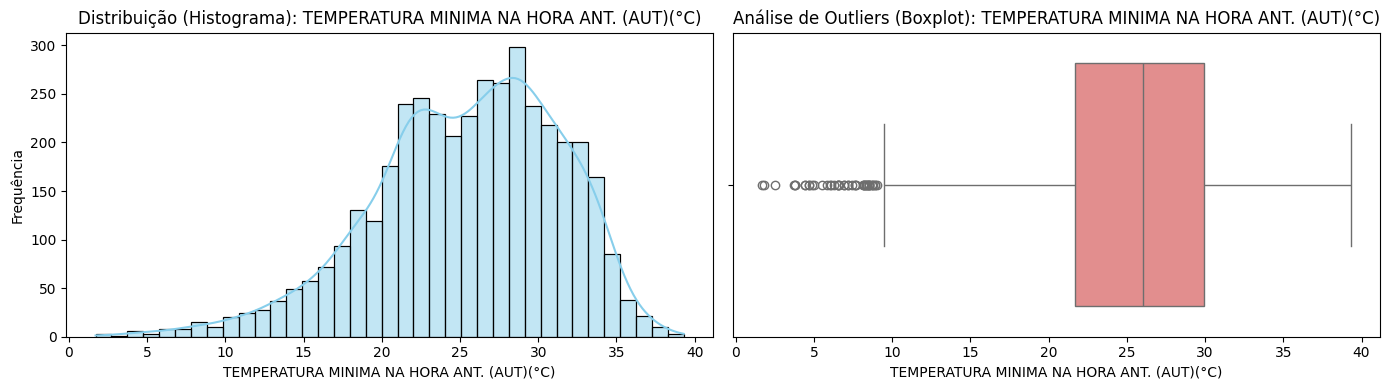

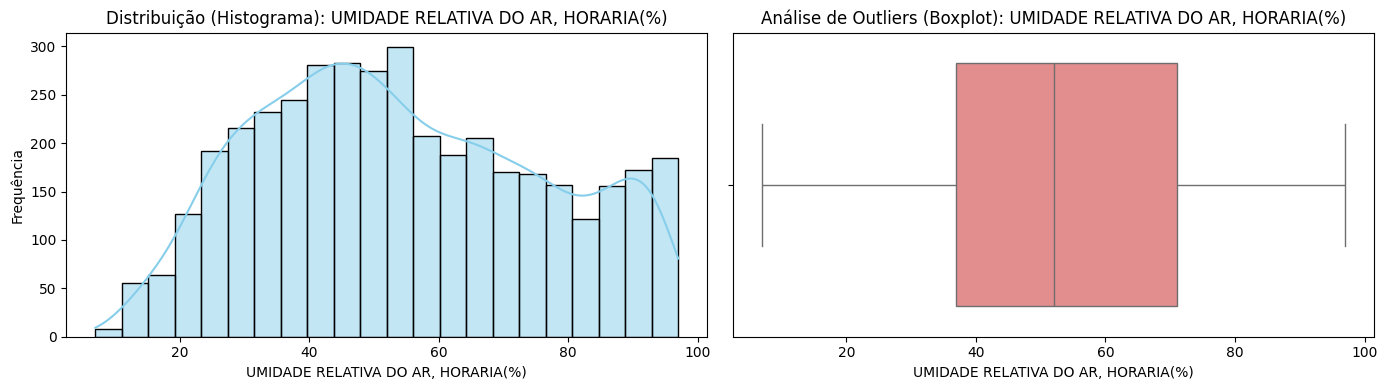

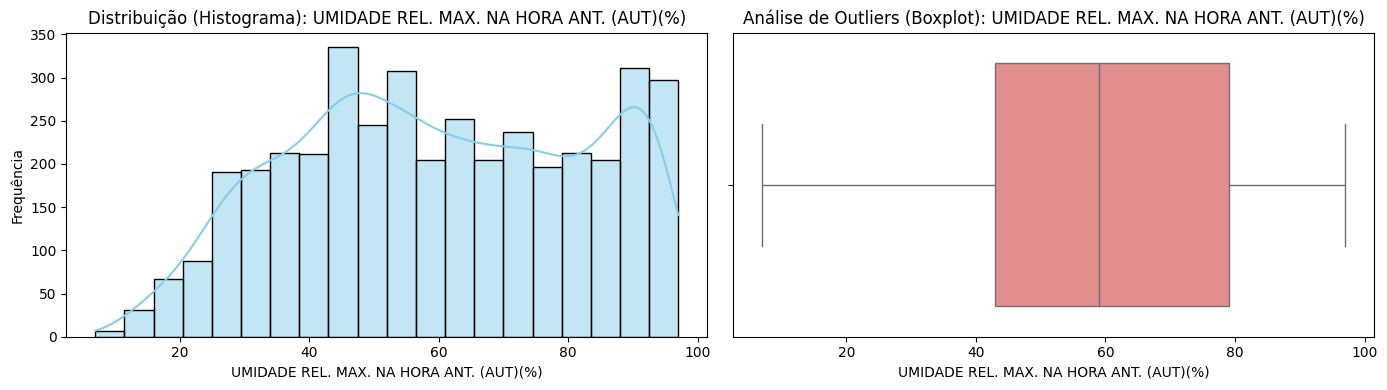

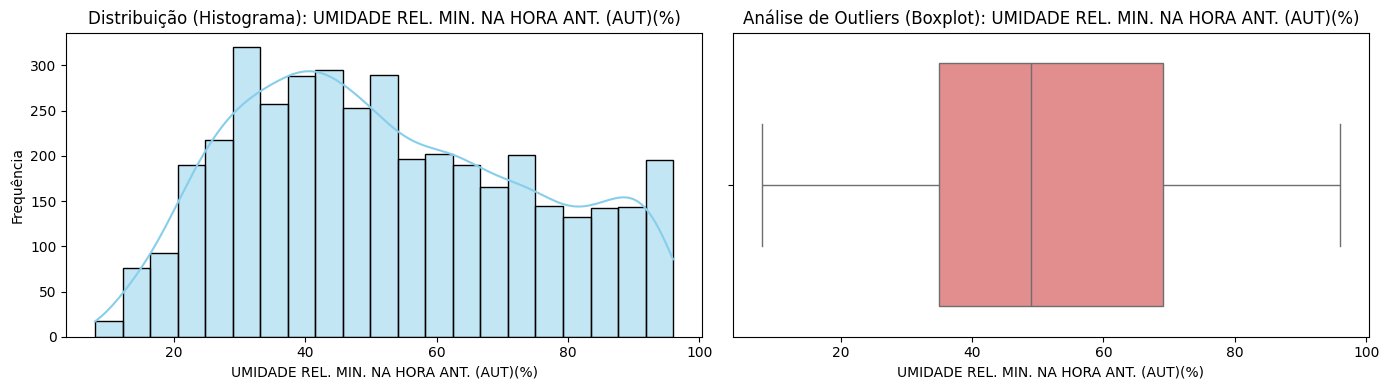

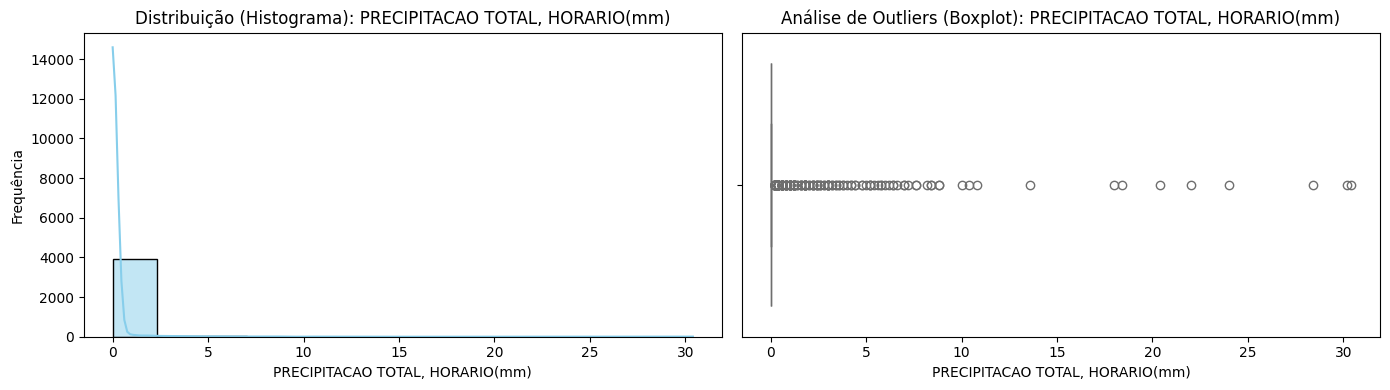

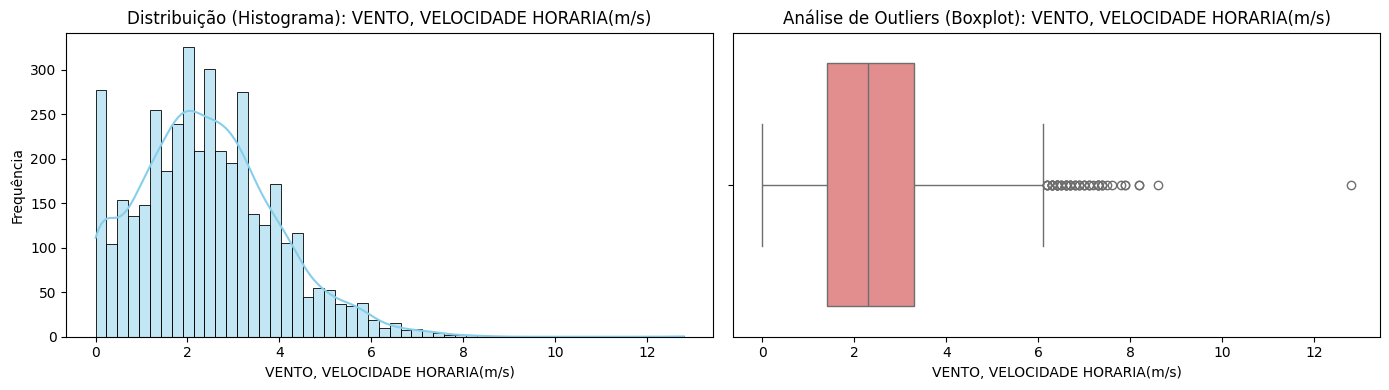

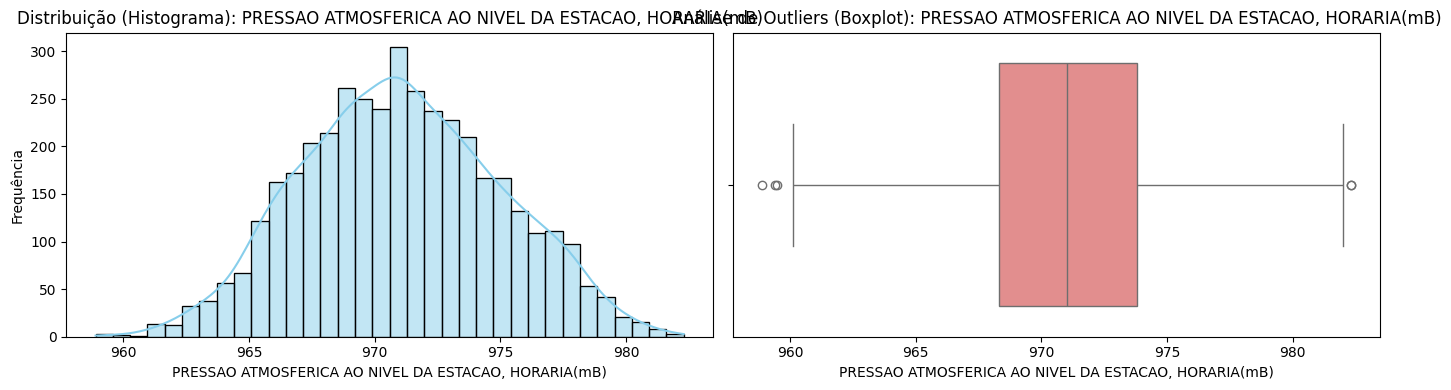

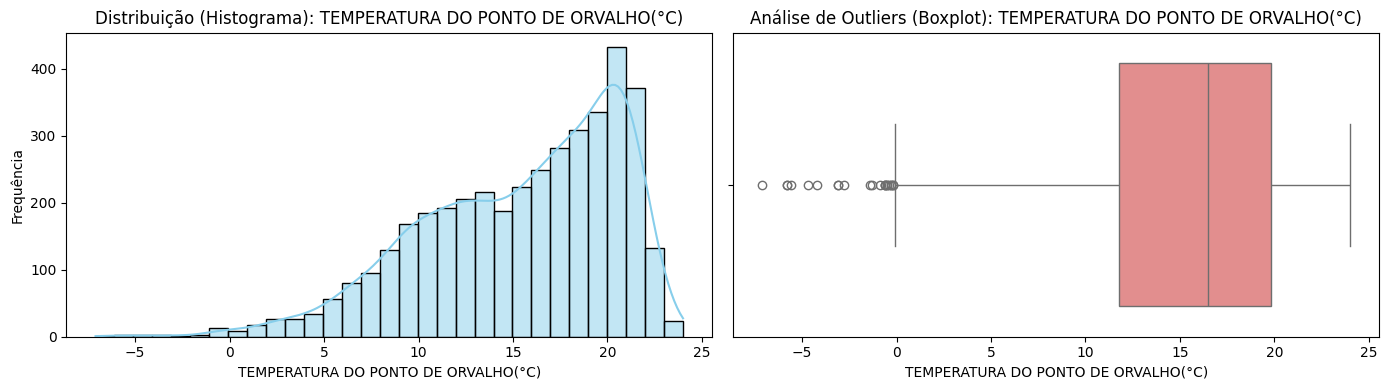

In [ ]:
plot_variable_distributions(df_valparaiso)

Melhor cenário de qualidade dos dados.
* Radiação Global Quase Perfeita (1.99% de NaNs): Ao contrário do apagão de $23\%$ em Dracena e do desastre de $96\%$ em Jales, Valparaíso tem quase o ano completo de radiação medido. O histograma mostra uma distribuição bem desenhada, cobrindo todas as faixas de intensidade (até $3878.8\text{ Kj/m}^2$)

* Erros Físicos Sob Controle (90 erros): Foram detectados 90 erros de radiação negativa (mínimo de $-3.5\text{ Kj/m}^2$)


* Demais Variáveis Saudáveis (~0.15% de NaNs): Temperatura, Vento, Umidade e Pressão possuem menos de $0.2\%$ de dados ausentes, o que significa um histórico contínuo e sem lacunas temporais. O vento atinge uma máxima de $12.8\text{ m/s}$, excelente para capturar o efeito de resfriamento dos painéis

## JOSE BONIFACIO A735

In [ ]:
print(df_estacoes[df_estacoes['Código']=='A735'])

               Nome  UF  Situação    Latitude   Longitude Altitude  \
141  JOSE BONIFACIO  SP  Operante  -21,085556  -49,920278   408,35   

    Data de Instalação Código  
141         02/09/2007   A735  


In [ ]:
df_josebon = extract_normalize_stations('A735')
df_josebon.head(1)

,datetime,hour_sin,hour_cos,month_sin,month_cos,RADIACAO GLOBAL(Kj/m²),TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),"UMIDADE RELATIVA DO AR, HORARIA(%)",UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),"PRECIPITACAO TOTAL, HORARIO(mm)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",TEMPERATURA DO PONTO DE ORVALHO(°C)
0,2025-01-01 07:00:00,0.965926,-0.258819,0.5,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df_josebon.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4015 entries, 0 to 4014
Data columns (total 15 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   datetime                                              4015 non-null   datetime64[ns]
 1   hour_sin                                              4015 non-null   float64       
 2   hour_cos                                              4015 non-null   float64       
 3   month_sin                                             4015 non-null   float64       
 4   month_cos                                             4015 non-null   float64       
 5   RADIACAO GLOBAL(Kj/m²)                                1887 non-null   float64       
 6   TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C)             2899 non-null   float64       
 7   TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C)             2899 non-null   float64 

In [ ]:
df_josebon_qualidade = analyze_data_quality(df_josebon)
df_josebon_qualidade

,valores_ausentes_pct,minimo,maximo,media,desvio_padrao,erros_fisicos_detectados
hour_sin,0.00,-0.965926,0.965926,1.243782e-16,0.674284,0.0
hour_cos,0.00,-1.000000,-0.258819,-6.905231e-01,0.262010,0.0
month_sin,0.00,-1.000000,1.000000,-5.381100e-03,0.705720,0.0
month_cos,0.00,-1.000000,1.000000,-2.372672e-03,0.708643,0.0
RADIACAO GLOBAL(Kj/m²),53.00,-3.500000,4968.300000,1.373360e+03,889.329360,43.0
TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),27.80,1.800000,39.800000,2.613170e+01,6.100769,0.0
TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),27.80,1.400000,38.100000,2.419020e+01,6.210524,0.0
"UMIDADE RELATIVA DO AR, HORARIA(%)",27.80,8.000000,99.000000,5.560642e+01,23.358297,0.0
UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),27.80,9.000000,99.000000,6.105036e+01,23.778297,0.0
UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),27.80,7.000000,98.000000,5.394653e+01,23.534717,0.0


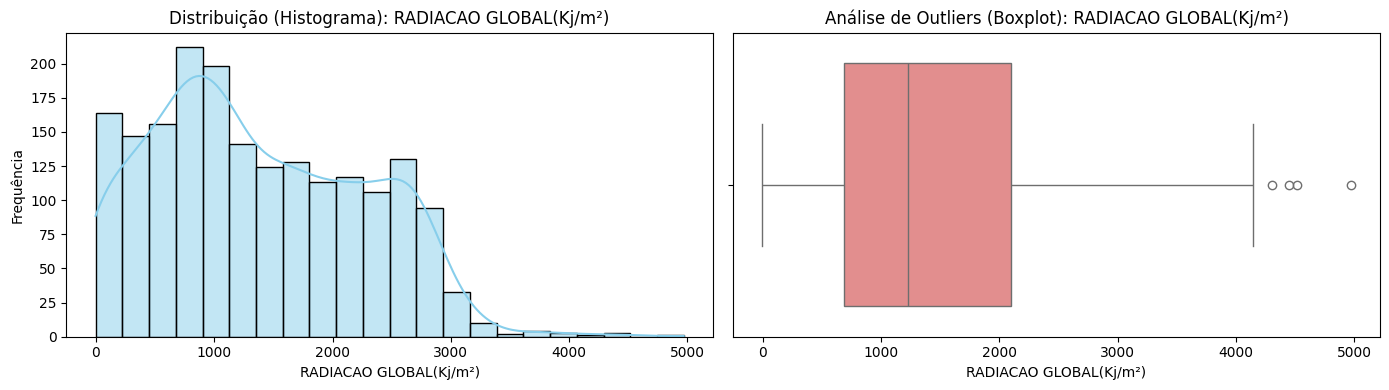

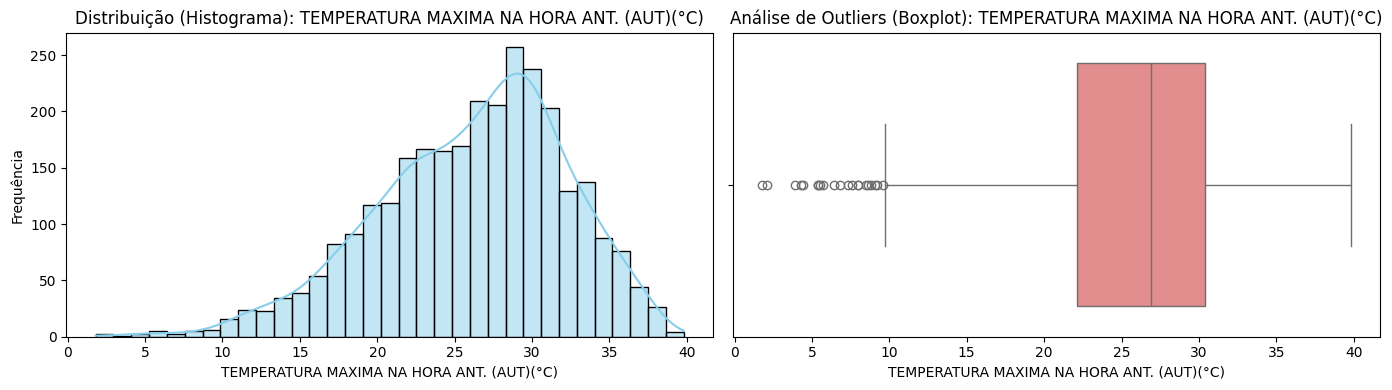

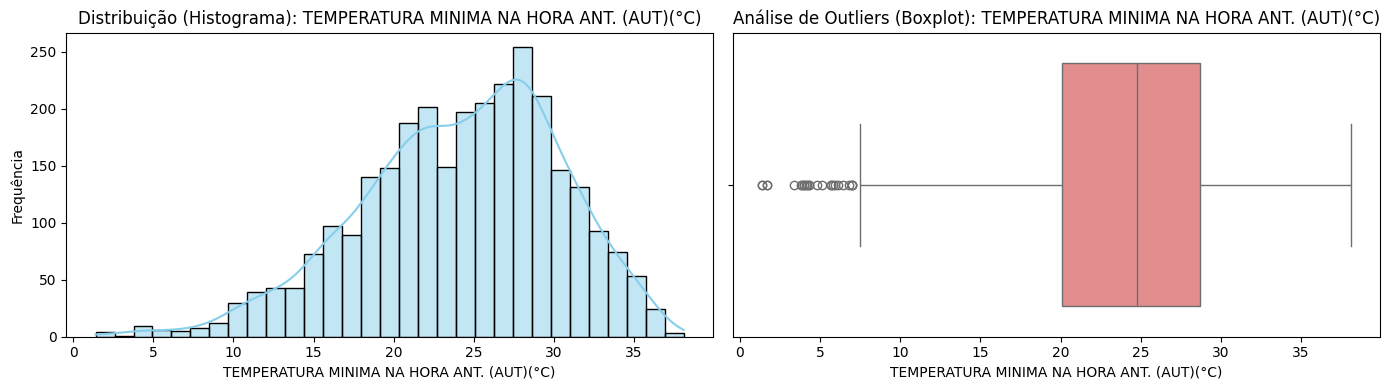

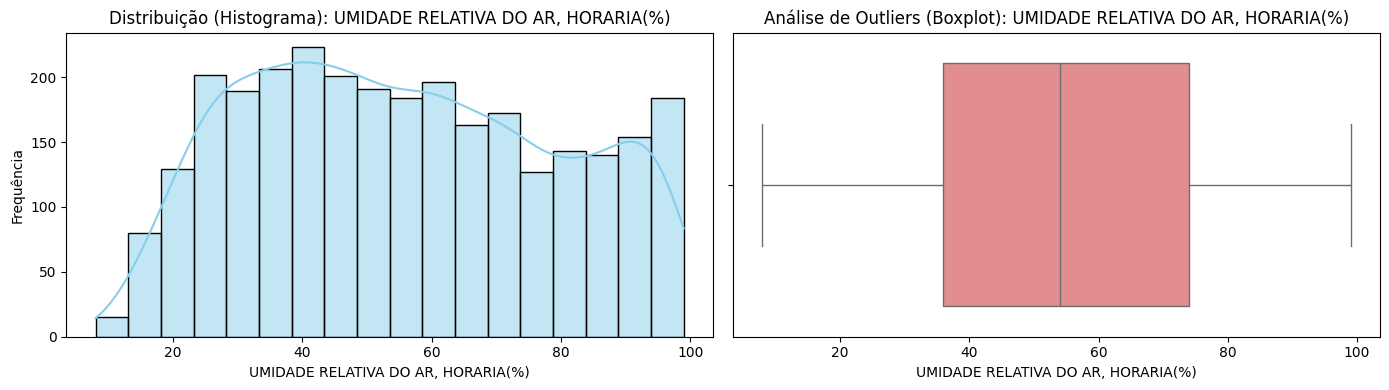

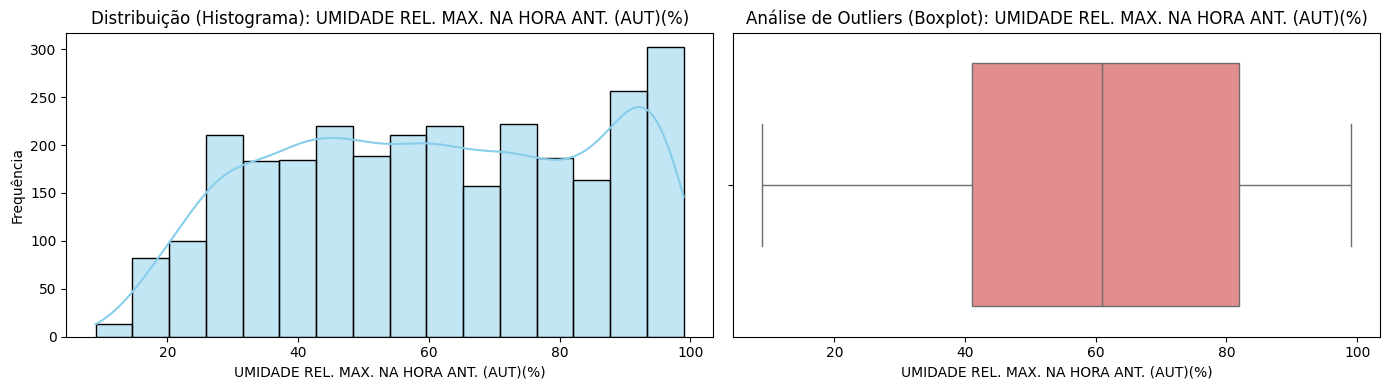

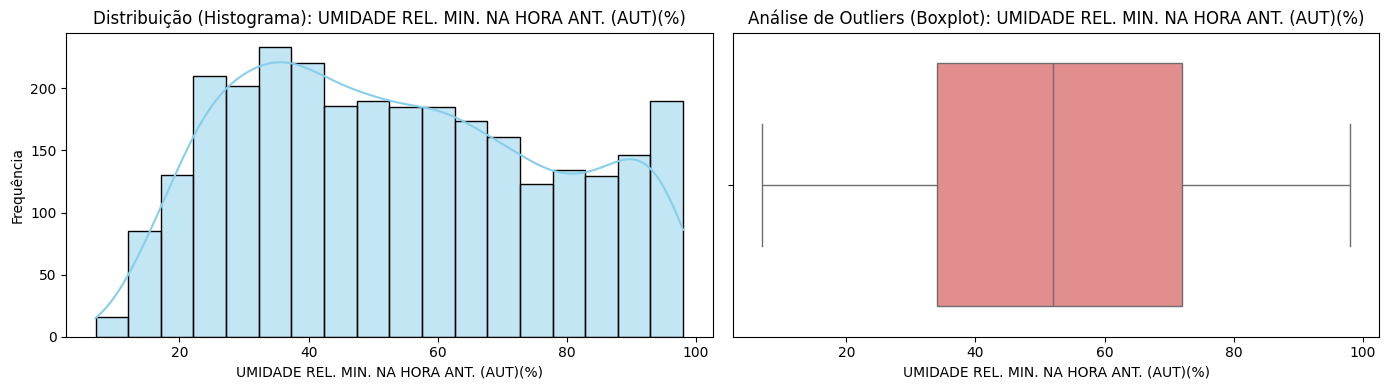

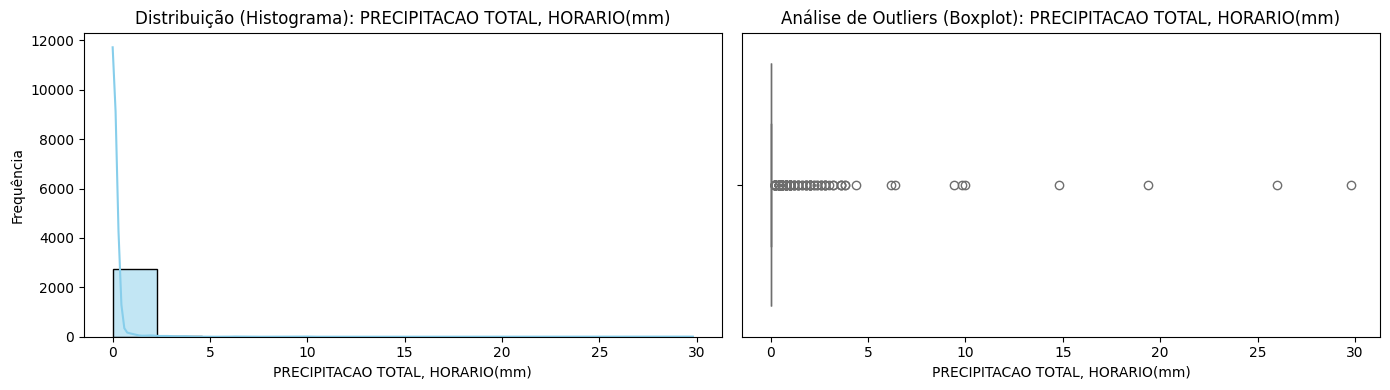

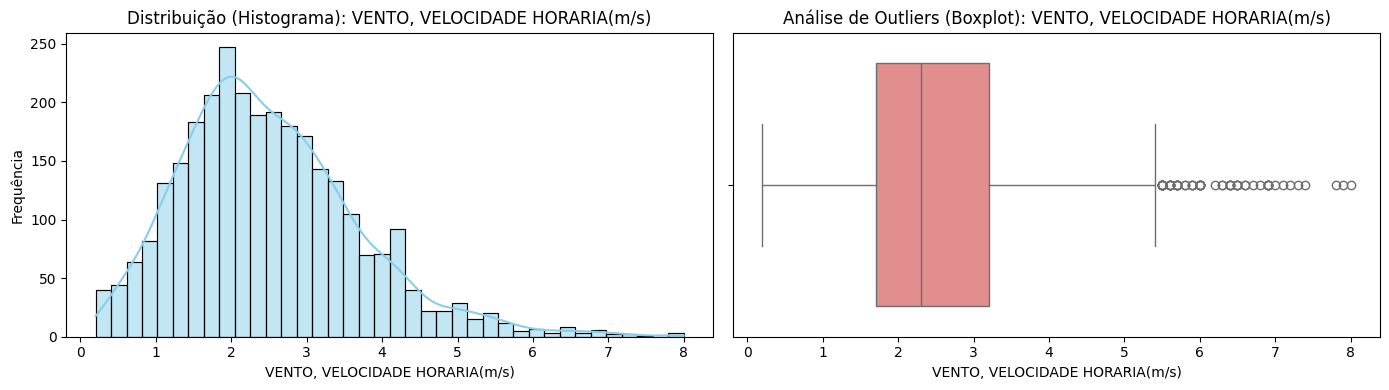

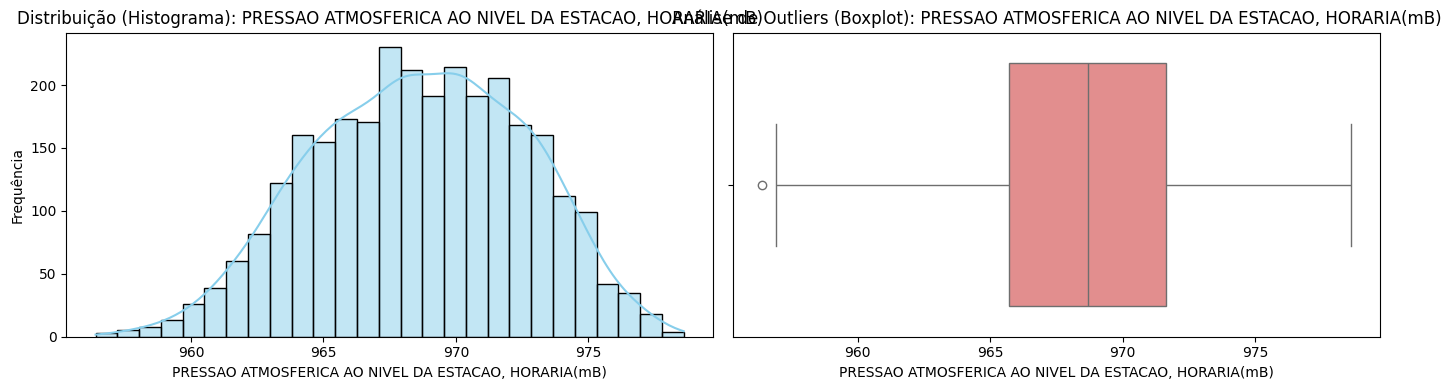

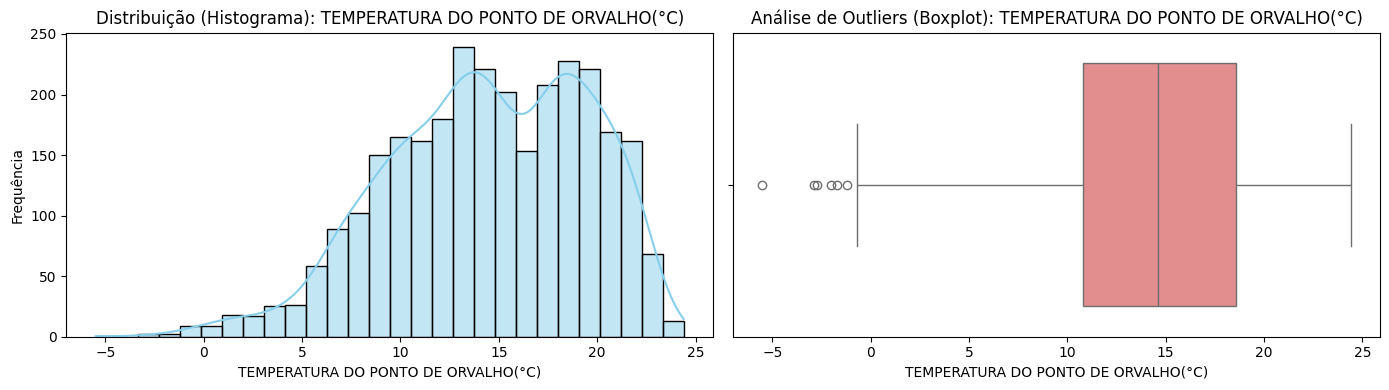

In [ ]:
plot_variable_distributions(df_josebon)

Alta Taxa de Dados Ausentes (~27.8% a 53%)   

Radiação Global (53.00% de NaNs) maior qntd de nulos que Dracena (23.04%)   



Não é uma boa estação para uso. **Descartar**



## PRESIDENTE PRUDENTE A707

In [ ]:
print(df_estacoes[df_estacoes['Código']=='A707'])

                    Nome  UF  Situação Latitude   Longitude Altitude  \
148  PRESIDENTE PRUDENTE  SP  Operante   -22,12  -51,408611   431,92   

    Data de Instalação Código  
148         03/02/2003   A707  


In [ ]:
df_presidentep = extract_normalize_stations('A707')
df_presidentep.head(1)

,datetime,hour_sin,hour_cos,month_sin,month_cos,RADIACAO GLOBAL(Kj/m²),TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),"UMIDADE RELATIVA DO AR, HORARIA(%)",UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),"PRECIPITACAO TOTAL, HORARIO(mm)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",TEMPERATURA DO PONTO DE ORVALHO(°C)
0,2025-01-01 07:00:00,0.965926,-0.258819,0.5,0.866025,136.5,24.5,23.4,80.0,83.0,80.0,0.0,2.4,962.0,20.8


In [ ]:
df_presidentep.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4015 entries, 0 to 4014
Data columns (total 15 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   datetime                                              4015 non-null   datetime64[ns]
 1   hour_sin                                              4015 non-null   float64       
 2   hour_cos                                              4015 non-null   float64       
 3   month_sin                                             4015 non-null   float64       
 4   month_cos                                             4015 non-null   float64       
 5   RADIACAO GLOBAL(Kj/m²)                                3994 non-null   float64       
 6   TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C)             3994 non-null   float64       
 7   TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C)             3994 non-null   float64 

In [ ]:
df_presidentep_qualidade = analyze_data_quality(df_presidentep)
df_presidentep_qualidade

,valores_ausentes_pct,minimo,maximo,media,desvio_padrao,erros_fisicos_detectados
hour_sin,0.00,-0.965926,0.965926,1.243782e-16,0.674284,0.0
hour_cos,0.00,-1.000000,-0.258819,-6.905231e-01,0.262010,0.0
month_sin,0.00,-1.000000,1.000000,-5.381100e-03,0.705720,0.0
month_cos,0.00,-1.000000,1.000000,-2.372672e-03,0.708643,0.0
RADIACAO GLOBAL(Kj/m²),0.52,-3.500000,3964.700000,1.545858e+03,1124.085887,75.0
TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),0.52,5.800000,39.400000,2.626405e+01,5.533011,0.0
TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),0.52,5.300000,38.200000,2.462904e+01,5.373293,0.0
"UMIDADE RELATIVA DO AR, HORARIA(%)",0.52,8.000000,99.000000,5.751452e+01,20.136957,0.0
UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),0.52,10.000000,99.000000,6.258488e+01,20.037291,0.0
UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),0.52,8.000000,99.000000,5.553781e+01,20.331406,0.0


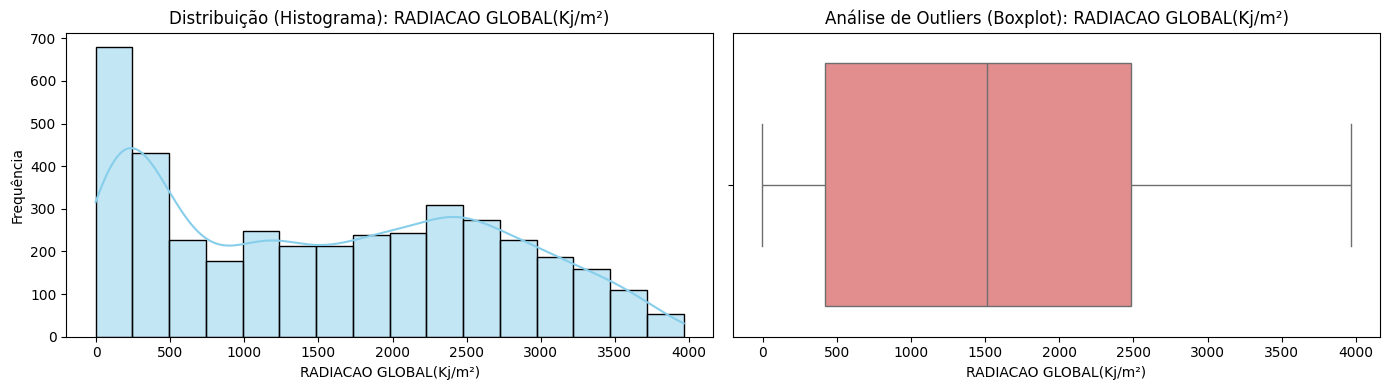

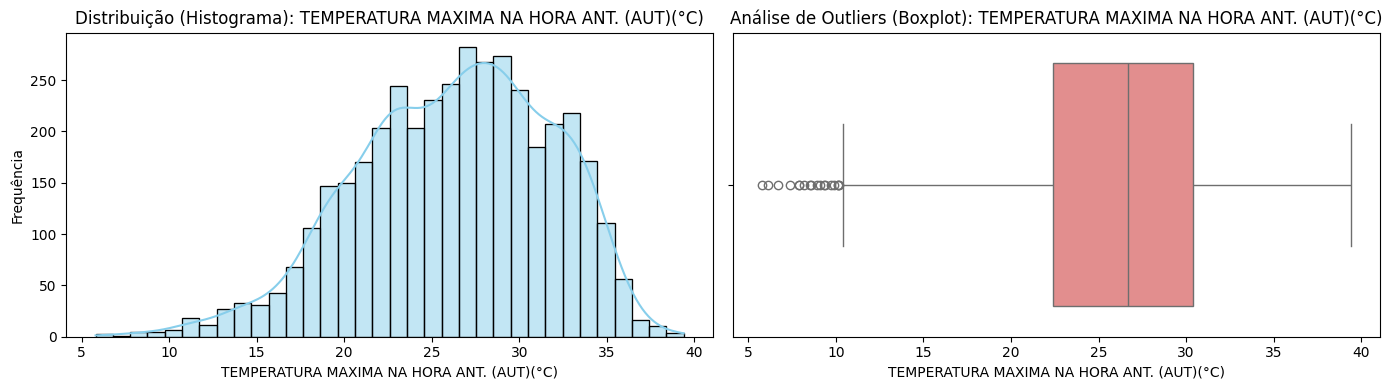

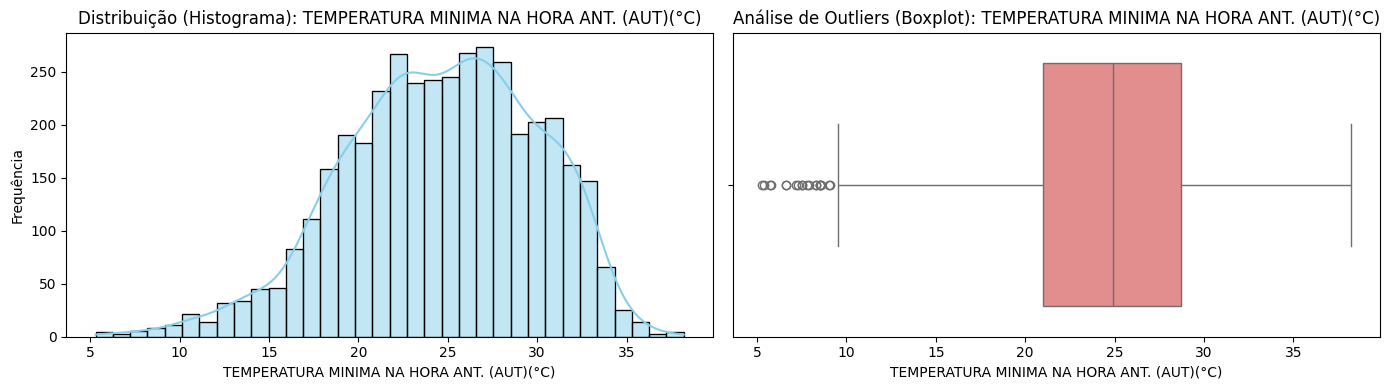

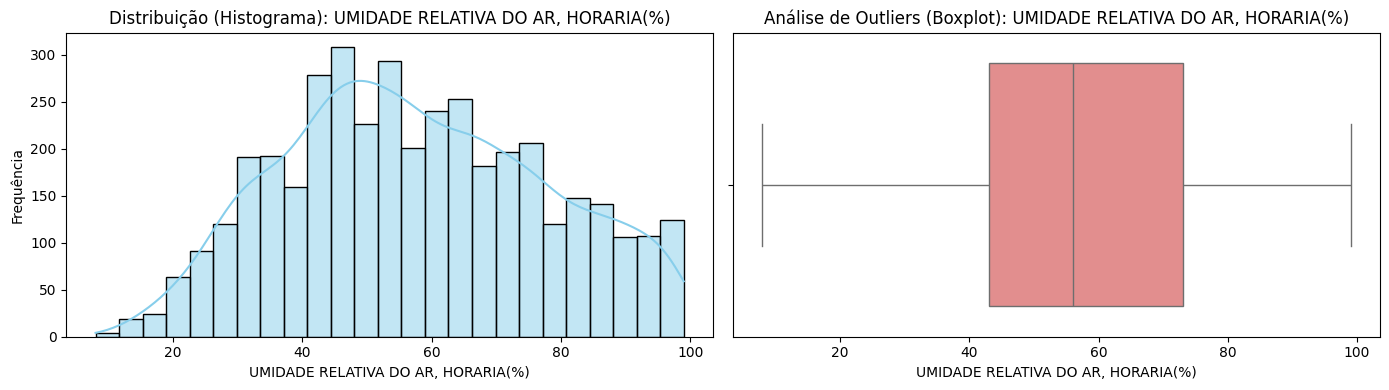

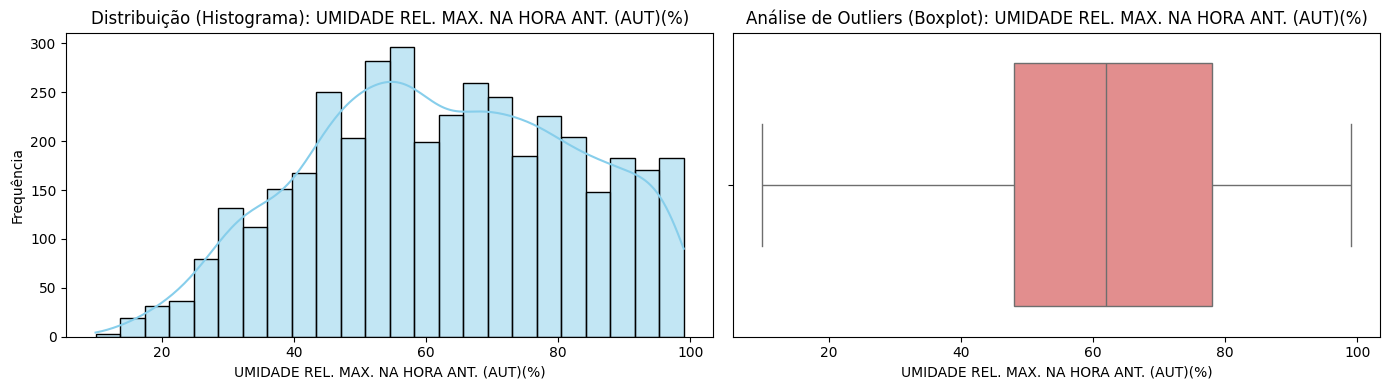

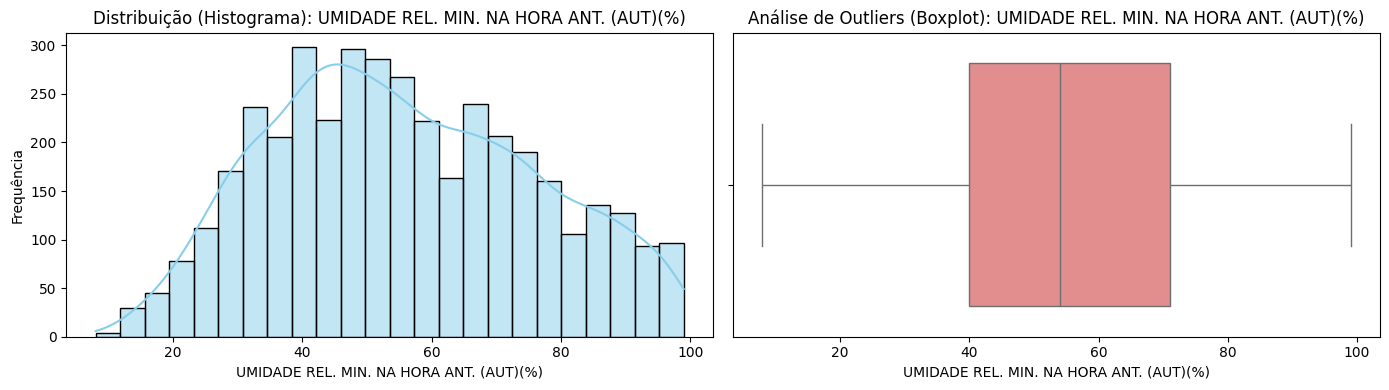

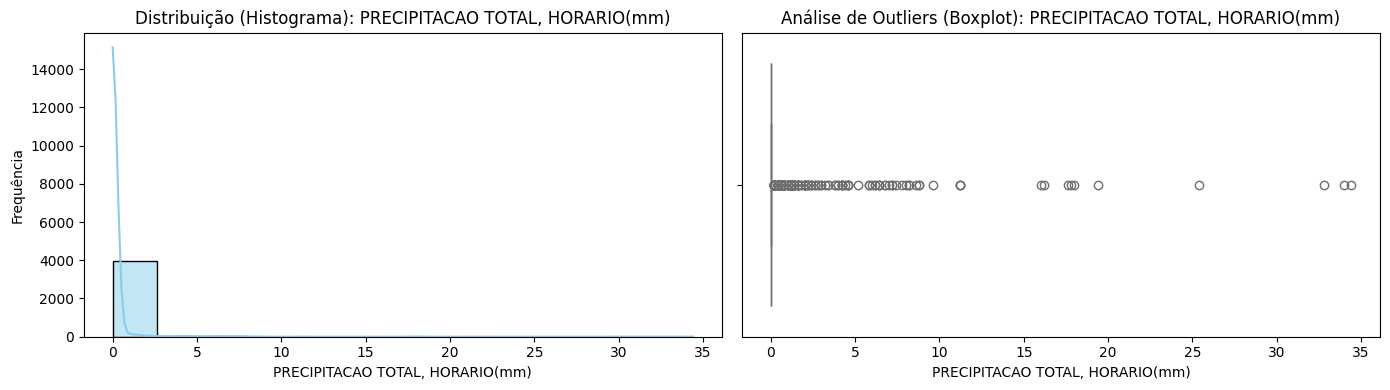

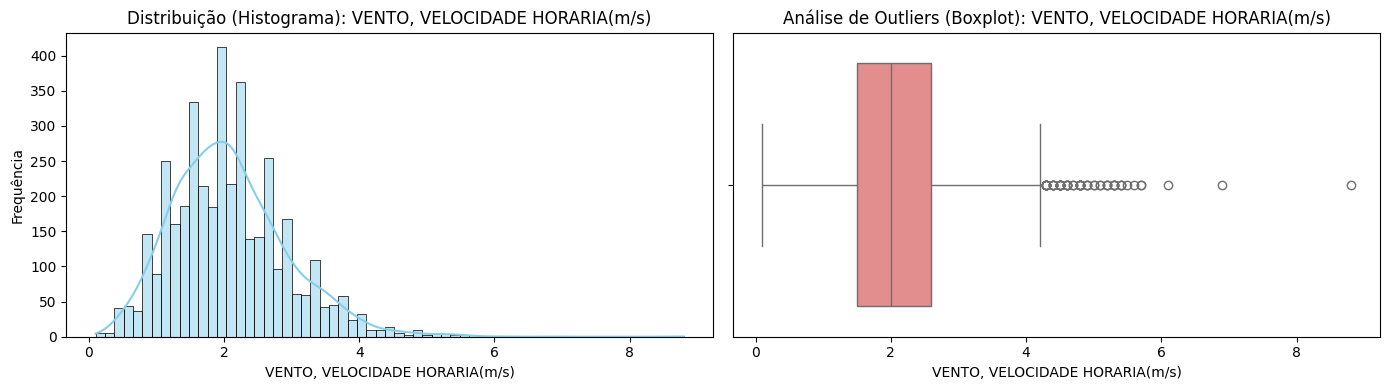

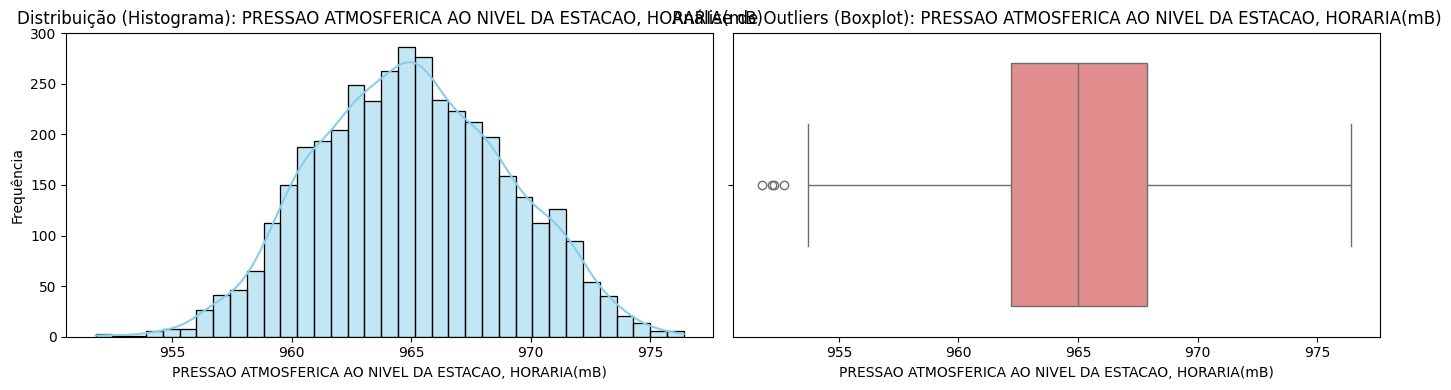

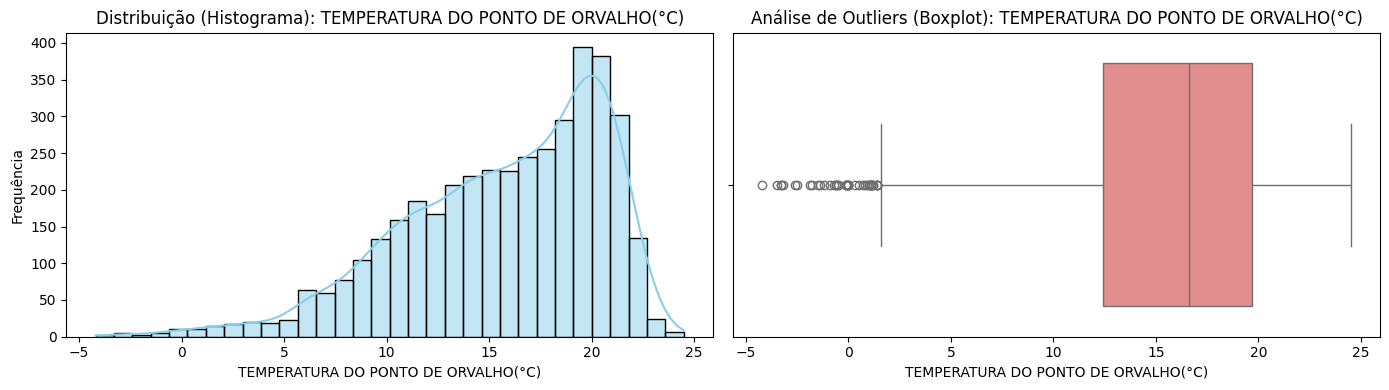

In [ ]:
plot_variable_distributions(df_presidentep)

Quase Zero Dados Ausentes (0.52%)

Para a fase de pré-processamento: Quase todas as estações apresentam uma radiação negativa nesse periodo 07-17 entre -3.6 e -3.5